# Job Market Analysis and Recommendation System

Dataset: `all_upwork_jobs_2024-02-07-2024-03-24.csv` (Upwork job postings).



## Load and audit the data

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 4))

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

_CSV = "all_upwork_jobs_2024-02-07-2024-03-24.csv"
RAW = next((p for p in (_CSV, "data/" + _CSV) if os.path.exists(p)), _CSV) 
df = pd.read_csv(RAW)
print("Raw shape:", df.shape)
df.head()

Raw shape: (244828, 8)


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [2]:
print("Missing share per column:")
print(df.isna().mean().round(3))

df["published_date"] = pd.to_datetime(df["published_date"], utc=True, errors="coerce")
print("\nDate range:", df["published_date"].min(), "->", df["published_date"].max())
print("Hourly share:", df["is_hourly"].mean().round(3))
df[["hourly_low", "hourly_high", "budget"]].describe(percentiles=[.5, .9, .99]).round(1)

Missing share per column:
title             0.000
link              0.000
published_date    0.000
is_hourly         0.000
hourly_low        0.582
hourly_high       0.597
budget            0.576
country           0.021
dtype: float64

Date range: 2023-11-02 09:22:02+00:00 -> 2024-03-24 14:16:47+00:00
Hourly share: 0.576


,hourly_low,hourly_high,budget
count,102422.0,98775.0,103891.0
mean,17.3,42.0,911.5
std,18.1,47.9,15729.7
min,3.0,3.0,5.0
50%,15.0,30.0,100.0
90%,35.0,80.0,1000.0
99%,75.0,200.0,10000.0
max,998.0,999.0,1000000.0


,hourly_low,hourly_high,budget
count,102422.0,98775.0,103891.0
mean,17.3,42.0,911.5
std,18.1,47.9,15729.7
min,3.0,3.0,5.0
50%,15.0,30.0,100.0
90%,35.0,80.0,1000.0
99%,75.0,200.0,10000.0
max,998.0,999.0,1000000.0


## Clean and preprocess
1. Drop empty titles and duplicates (same title + timestamp).
2. Keep the dense posting window (from 2024-02-12); earlier rows are sparse stragglers.
3. Build `hourly_mid` (hourly jobs) and `fixed_budget` (fixed-price jobs). 
4. Remove the top 1% of each (extreme outliers such as a 1,000,000 budget).
5. Clean titles (lowercase, expand abbreviations, strip punctuation).

In [3]:
before = len(df)
df = df.dropna(subset=["title"]).drop_duplicates(subset=["title", "published_date"])
print(f"Dropped {before - len(df)} duplicate/empty rows")

START = pd.Timestamp("2024-02-12", tz="UTC")
df = df[df["published_date"] >= START].copy()
print("Rows in dense window:", len(df))

df["hourly_mid"] = df[["hourly_low", "hourly_high"]].mean(axis=1)
df["fixed_budget"] = df["budget"].where(~df["is_hourly"])

df.loc[df["hourly_mid"] > df["hourly_mid"].quantile(0.99), "hourly_mid"] = np.nan
df.loc[df["fixed_budget"] > df["fixed_budget"].quantile(0.99), "fixed_budget"] = np.nan

ABBREV = {r"\bsr\.?\b": "senior", r"\bjr\.?\b": "junior", r"\bva\b": "virtual assistant"}

def clean_title(t):
    t = t.lower()
    for pat, rep in ABBREV.items():
        t = re.sub(pat, rep, t)
    t = re.sub(r"[^a-z0-9+#\s]", " ", t)   # keep c++, c#
    return re.sub(r"\s+", " ", t).strip()

df["title_clean"] = df["title"].apply(clean_title)
SPANISH = set("para de la el los las y en un una con por nuestro trabajo que se del al es".split())
is_spanish = df["title_clean"].apply(lambda s: sum(w in SPANISH for w in s.split()) >= 2)
non_latin = df["title"].apply(lambda s: any(ord(ch) > 591 for ch in s))
df["is_english_like"] = ~(is_spanish | non_latin) & (df["title_clean"].str.len() > 2)
print("English-like titles kept:", df["is_english_like"].mean().round(4))
df["date"] = df["published_date"].dt.tz_localize(None).dt.normalize()
df["week"] = df["published_date"].dt.tz_localize(None).dt.to_period("W").astype(str)
df["country"] = df["country"].fillna("Unknown")

df[["title", "title_clean", "is_english_like", "hourly_mid", "fixed_budget", "country"]].head(8)

Dropped 15 duplicate/empty rows
Rows in dense window: 244561
English-like titles kept: 0.9878


,title,title_clean,is_english_like,hourly_mid,fixed_budget,country
0,Experienced Media Buyer For Solar Pannel and R...,experienced media buyer for solar pannel and r...,True,NaN,500.0,Unknown
1,Full Stack Developer,full stack developer,True,NaN,1100.0,United States
2,SMMA Bubble App,smma bubble app,True,20.0,NaN,United States
3,Talent Hunter Specialized in Marketing,talent hunter specialized in marketing,True,NaN,NaN,United States
4,Data Engineer,data engineer,True,NaN,650.0,India
5,SEO for Portuguese Psychologist site,seo for portuguese psychologist site,True,NaN,NaN,Portugal
6,Want to fix the WordPress Plugin,want to fix the wordpress plugin,True,NaN,5.0,India
7,need Portuguese writers who can understand and...,need portuguese writers who can understand and...,True,14.5,NaN,India


,title,title_clean,is_english_like,hourly_mid,fixed_budget,country
0,Experienced Media Buyer For Solar Pannel and R...,experienced media buyer for solar pannel and r...,True,NaN,500.0,Unknown
1,Full Stack Developer,full stack developer,True,NaN,1100.0,United States
2,SMMA Bubble App,smma bubble app,True,20.0,NaN,United States
3,Talent Hunter Specialized in Marketing,talent hunter specialized in marketing,True,NaN,NaN,United States
4,Data Engineer,data engineer,True,NaN,650.0,India
5,SEO for Portuguese Psychologist site,seo for portuguese psychologist site,True,NaN,NaN,Portugal
6,Want to fix the WordPress Plugin,want to fix the wordpress plugin,True,NaN,5.0,India
7,need Portuguese writers who can understand and...,need portuguese writers who can understand and...,True,14.5,NaN,India


##  Exploratory data analysis

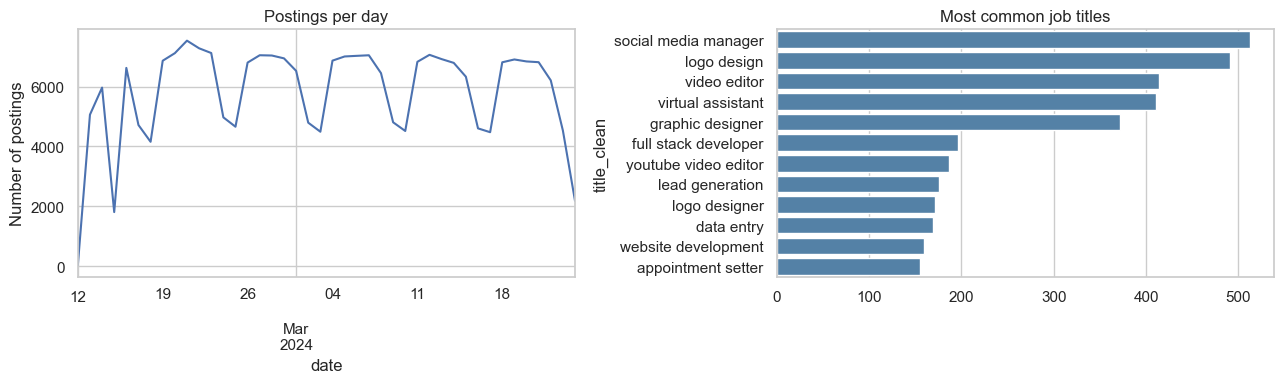

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

daily = df.groupby("date").size()
daily.plot(ax=axes[0])
axes[0].set_title("Postings per day")
axes[0].set_ylabel("Number of postings")

top_titles = df["title_clean"].value_counts().head(12)
sns.barplot(x=top_titles.values, y=top_titles.index, ax=axes[1], color="steelblue")
axes[1].set_title("Most common job titles")
plt.tight_layout(); plt.show()

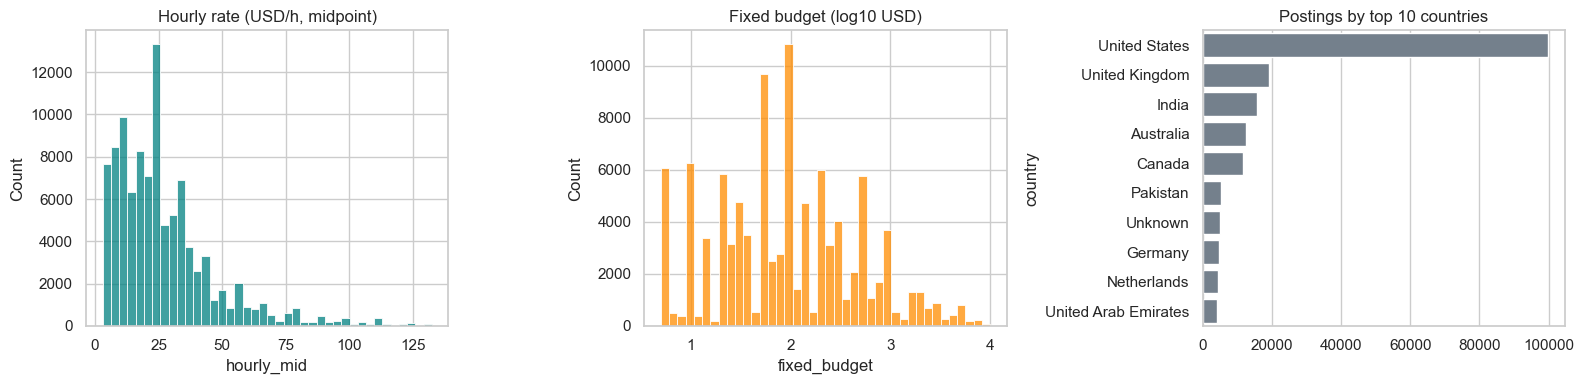

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["hourly_mid"].dropna(), bins=40, ax=axes[0], color="teal")
axes[0].set_title("Hourly rate (USD/h, midpoint)")

sns.histplot(np.log10(df["fixed_budget"].dropna()), bins=40, ax=axes[1], color="darkorange")
axes[1].set_title("Fixed budget (log10 USD)")

top_c = df["country"].value_counts().head(10)
sns.barplot(x=top_c.values, y=top_c.index, ax=axes[2], color="slategray")
axes[2].set_title("Postings by top 10 countries")
plt.tight_layout(); plt.show()

## Correlation between title keywords and offered salary

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

hourly = df[df["is_hourly"] & df["hourly_mid"].notna() & df["is_english_like"]].copy()
print("Hourly rows with a rate:", len(hourly))

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=100, stop_words="english")
X = vec.fit_transform(hourly["title_clean"])
y = np.log1p(hourly["hourly_mid"].values)
terms = np.array(vec.get_feature_names_out())
print("Keyword features:", X.shape[1])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model = Ridge(alpha=1.0).fit(X_tr, y_tr)
pred = model.predict(X_te)
print(f"Holdout R2: {r2_score(y_te, pred):.3f}")
print(f"Holdout MAE (USD/h): {mean_absolute_error(np.expm1(y_te), np.expm1(pred)):.2f}")

Hourly rows with a rate: 99989
Keyword features: 887
Holdout R2: 0.253
Holdout MAE (USD/h): 12.34


Keyword features: 887
Holdout R2: 0.253
Holdout MAE (USD/h): 12.34


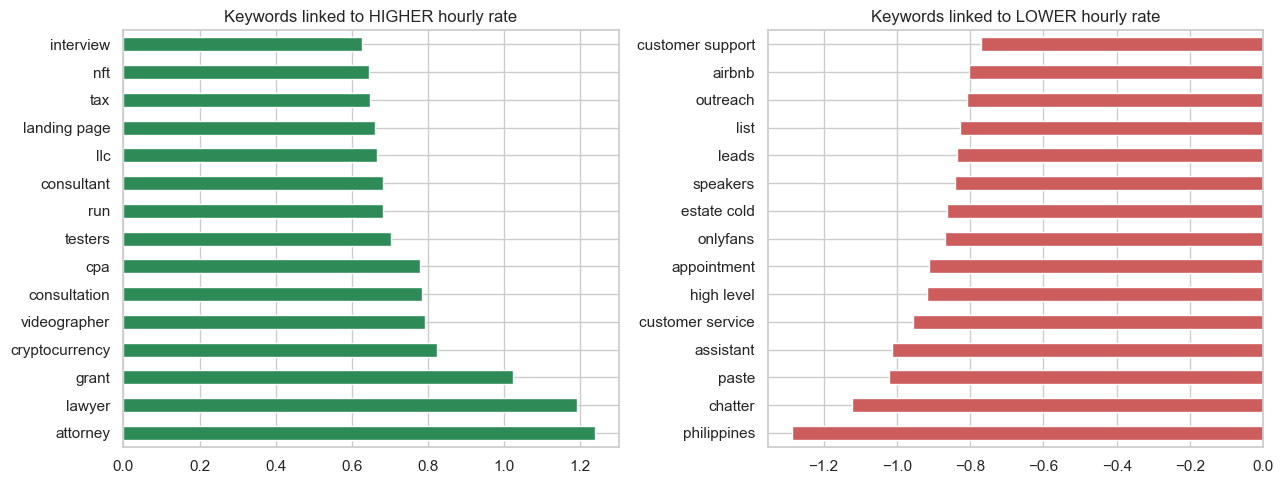

In [7]:
coef = pd.Series(model.coef_, index=terms).sort_values()
top_neg, top_pos = coef.head(15), coef.tail(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_pos[::-1].plot.barh(ax=axes[0], color="seagreen"); axes[0].set_title("Keywords linked to HIGHER hourly rate")
top_neg.plot.barh(ax=axes[1], color="indianred"); axes[1].set_title("Keywords linked to LOWER hourly rate")
plt.tight_layout(); plt.show()

In [8]:
from scipy.stats import mannwhitneyu

rows = []
for kw in list(top_pos.index[-10:]) + list(top_neg.index[:10]):
    has = hourly["title_clean"].str.contains(rf"\b{re.escape(kw)}\b", regex=True)
    a, b = hourly.loc[has, "hourly_mid"], hourly.loc[~has, "hourly_mid"]
    if len(a) >= 30:
        p = mannwhitneyu(a, b, alternative="two-sided").pvalue
        rows.append({"keyword": kw, "n_titles": len(a),
                     "median_with": a.median(), "median_without": b.median(),
                     "p_value": p})

kw_table = pd.DataFrame(rows).sort_values("median_with", ascending=False)
kw_table["median_diff"] = kw_table["median_with"] - kw_table["median_without"]
kw_table.round(4)

,keyword,n_titles,median_with,median_without,p_value,median_diff
9,attorney,145,87.5,22.5,0.0000,65.0
8,lawyer,185,82.0,22.5,0.0000,59.5
7,grant,170,57.5,22.5,0.0000,35.0
6,cryptocurrency,229,55.0,22.5,0.0000,32.5
3,cpa,184,52.5,22.5,0.0000,30.0
4,consultation,320,45.0,22.5,0.0000,22.5
5,videographer,394,42.5,22.5,0.0000,20.0
0,consultant,883,40.0,22.5,0.0000,17.5
2,testers,103,40.0,22.5,0.0000,17.5
1,run,161,37.5,22.5,0.0000,15.0


## Identify emerging job categories based on posting frequency


In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.cluster import MiniBatchKMeans
from scipy.stats import chi2_contingency

d2 = df[df["is_english_like"]].copy()
A = d2[(d2["date"] >= "2024-02-19") & (d2["date"] < "2024-03-04")]
B = d2[(d2["date"] >= "2024-03-04") & (d2["date"] < "2024-03-18")]
print(f"Period A: {len(A):,} postings | Period B: {len(B):,} postings")

def bh_fdr(p):
    """Benjamini-Hochberg adjusted p-values."""
    p = np.asarray(p, dtype=float); n = len(p); order = np.argsort(p)
    adj = np.minimum.accumulate((p[order] * n / (np.arange(n) + 1))[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1)
    return out

def compare_periods(count_a, count_b, n_a, n_b):
    """Share change + chi-square p-value for arrays of counts."""
    res = pd.DataFrame({"count_A": count_a, "count_B": count_b})
    res["share_A_per10k"] = res["count_A"] / n_a * 1e4
    res["share_B_per10k"] = res["count_B"] / n_b * 1e4
    res["growth_ratio"] = res["share_B_per10k"] / res["share_A_per10k"]
    res["p_value"] = [
        chi2_contingency([[a, n_a - a], [b, n_b - b]], correction=False)[1]
        for a, b in zip(res["count_A"], res["count_B"])
    ]
    res["fdr"] = bh_fdr(res["p_value"])
    return res

Period A: 88,121 postings | Period B: 85,671 postings


### 2A. Data-driven categories: cluster similar titles

In [10]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=30, stop_words="english", max_features=8000)
X_all = tfidf.fit_transform(d2["title_clean"])
Z = Normalizer().fit_transform(TruncatedSVD(100, random_state=0).fit_transform(X_all))

K = 40
km = MiniBatchKMeans(K, random_state=0, n_init=5, batch_size=4096).fit(Z)
d2["cluster"] = km.labels_

t_terms = np.array(tfidf.get_feature_names_out())
labels = {}
for c in range(K):
    m = np.asarray(X_all[np.where(d2["cluster"].values == c)[0]].mean(axis=0)).ravel()
    labels[c] = ", ".join(t_terms[m.argsort()[::-1][:4]])

A = d2.loc[A.index]; B = d2.loc[B.index]
ca = A["cluster"].value_counts().reindex(range(K), fill_value=0)
cb = B["cluster"].value_counts().reindex(range(K), fill_value=0)
clusters = compare_periods(ca.values, cb.values, len(A), len(B))
clusters["category (top terms)"] = [labels[c] for c in range(K)]
clusters["n_titles"] = d2["cluster"].value_counts().reindex(range(K)).values
clusters["note"] = np.where(clusters["n_titles"] > 0.15 * len(d2), "catch-all cluster", "")
clusters["change_pct"] = (clusters["growth_ratio"] - 1) * 100
cols = ["category (top terms)", "n_titles", "share_A_per10k", "share_B_per10k", "change_pct", "fdr", "note"]
clusters.sort_values("change_pct", ascending=False)[cols].round(3)

C:\Users\Hp\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Hp\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Hp\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Hp\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

,category (top terms),n_titles,share_A_per10k,share_B_per10k,change_pct,fdr,note
34,"appointment, setter, appointment setter, cold",1469,56.854,63.615,11.893,0.212,
25,"ui, ux, ui ux, designer",2414,96.004,106.687,11.127,0.116,
10,"video, video editing, editing, short",5236,207.669,227.498,9.548,0.037,
0,"logo, logo design, design, logo designer",4881,194.959,213.024,9.266,0.044,
22,"ai, chatbot, developer, ai developer",3591,144.460,156.412,8.273,0.163,
3,"google, ads, google ads, facebook",6473,258.508,279.675,8.188,0.043,
19,"marketing, digital, digital marketing, marketi...",4646,182.817,194.698,6.499,0.212,
28,"design, website design, graphic design, website",6608,266.565,281.309,5.531,0.212,
15,"real, estate, real estate, cold",2490,102.359,106.921,4.456,0.750,
4,"editor, video editor, video, youtube",5604,228.209,238.004,4.292,0.469,


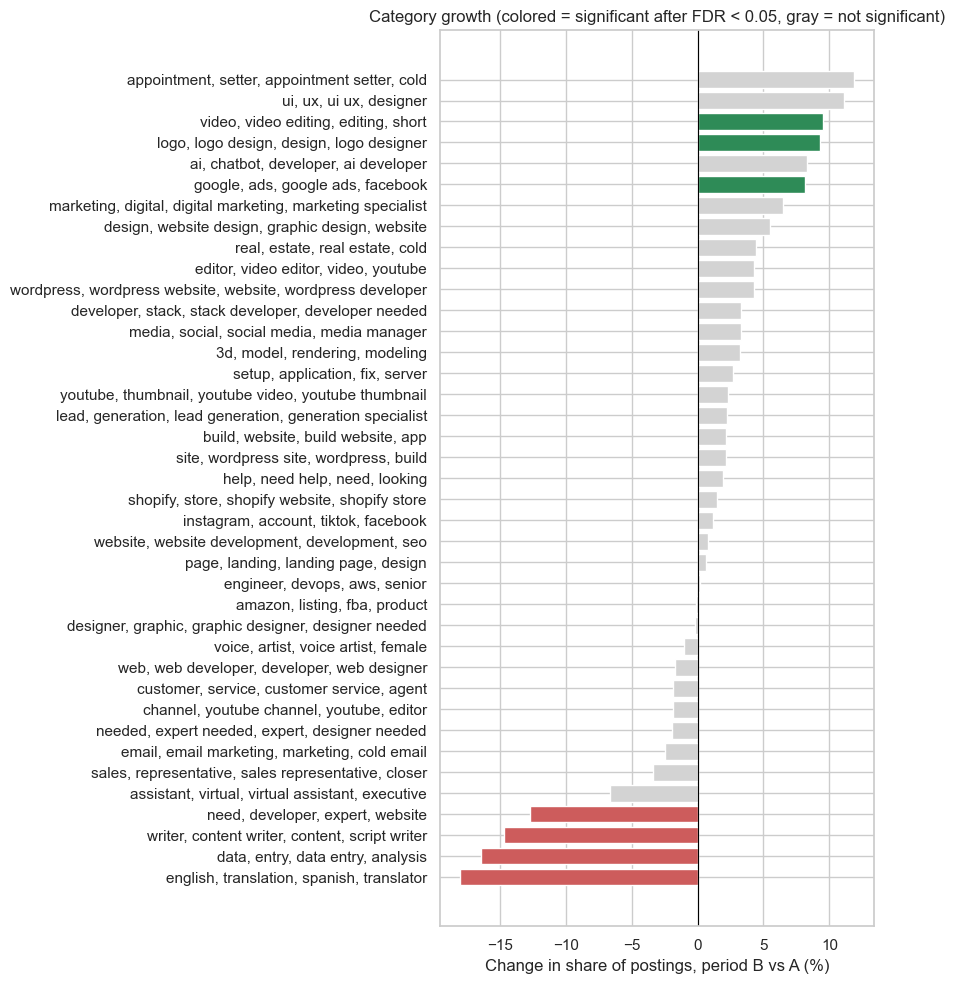

In [11]:
plot_df = clusters[clusters["note"] == ""].sort_values("change_pct")
colors = np.where(plot_df["fdr"] < 0.05, np.where(plot_df["change_pct"] > 0, "seagreen", "indianred"), "lightgray")
fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(plot_df["category (top terms)"], plot_df["change_pct"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in share of postings, period B vs A (%)")
ax.set_title("Category growth (colored = significant after FDR < 0.05, gray = not significant)")
plt.tight_layout(); plt.show()

### 2B. Keyword-level emergence (finer view)

In [12]:
cv = CountVectorizer(ngram_range=(1, 2), min_df=100, stop_words="english", binary=True)
cv.fit(pd.concat([A["title_clean"], B["title_clean"]]))
kw = np.array(cv.get_feature_names_out())
ka = np.asarray(cv.transform(A["title_clean"]).sum(axis=0)).ravel()
kb = np.asarray(cv.transform(B["title_clean"]).sum(axis=0)).ravel()

terms_df = compare_periods(ka, kb, len(A), len(B))
terms_df.insert(0, "keyword", kw)
terms_df = terms_df[(terms_df["count_A"] + terms_df["count_B"]) >= 300].copy()
terms_df["fdr"] = bh_fdr(terms_df["p_value"])           
terms_df["change_pct"] = (terms_df["growth_ratio"] - 1) * 100
print("Keywords tested:", len(terms_df))

# Emerging = significant after FDR AND at least +15% share growth
emerging = terms_df[(terms_df["fdr"] < 0.05) & (terms_df["growth_ratio"] >= 1.15)] \
              .sort_values("growth_ratio", ascending=False)
declining = terms_df[(terms_df["fdr"] < 0.05) & (terms_df["growth_ratio"] <= 1 / 1.15)] \
              .sort_values("growth_ratio")
show = ["keyword", "count_A", "count_B", "share_A_per10k", "share_B_per10k", "change_pct", "fdr"]
print(f"\nEMERGING keywords ({len(emerging)}):")
display(emerging[show].head(20).round(3))
print(f"DECLINING keywords ({len(declining)}):")
display(declining[show].head(15).round(3))

Keywords tested: 546

EMERGING keywords (7):


,keyword,count_A,count_B,share_A_per10k,share_B_per10k,change_pct,fdr
1140,recruiter,142,216,16.114,25.213,56.463,0.001
950,node js,128,194,14.525,22.645,55.897,0.002
351,crypto,310,430,35.179,50.192,42.676,0.000
1040,play,173,235,19.632,27.431,39.723,0.012
753,js,527,694,59.804,81.008,35.455,0.000
949,node,201,257,22.810,29.998,31.517,0.045
47,ads,1719,1923,195.073,224.463,15.067,0.000


DECLINING keywords (27):


,keyword,count_A,count_B,share_A_per10k,share_B_per10k,change_pct,fdr
1000,paste,363,161,41.193,18.793,-54.379,0.000
593,freelancers,281,125,31.888,14.591,-54.244,0.000
610,general,220,111,24.966,12.957,-48.103,0.000
1544,writer needed,198,110,22.469,12.840,-42.856,0.000
371,data entry,850,497,96.458,58.013,-39.857,0.000
1535,words,273,161,30.980,18.793,-39.339,0.000
326,copy,655,392,74.330,45.756,-38.441,0.000
748,job,934,564,105.991,65.833,-37.888,0.000
843,manual,220,133,24.966,15.525,-37.817,0.000
1547,writing,697,422,79.096,49.258,-37.723,0.000


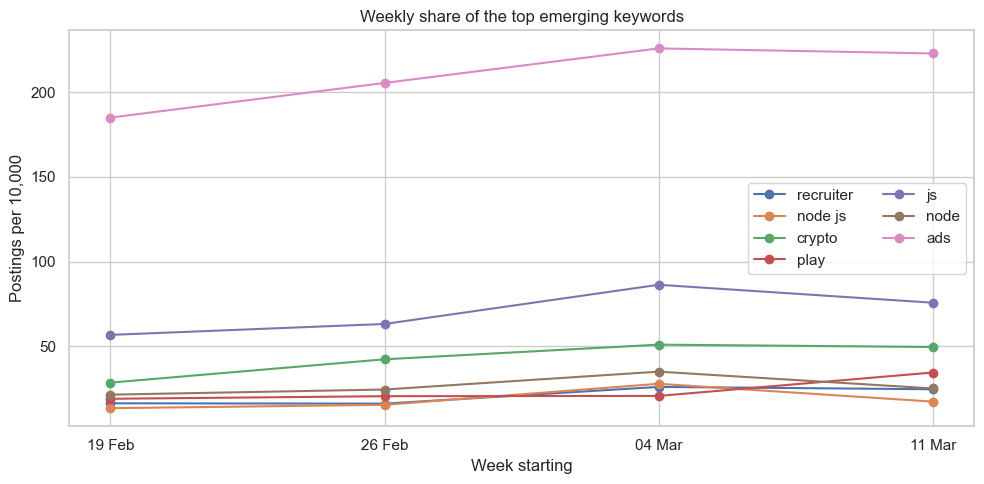

In [13]:
# Weekly share of the top rising keywords across the 4 full weeks
full_weeks = pd.to_datetime(["2024-02-19", "2024-02-26", "2024-03-04", "2024-03-11"])
d2["week_start"] = d2["date"] - pd.to_timedelta(d2["date"].dt.weekday, unit="D")
wk = d2[d2["week_start"].isin(full_weeks)]
wk_total = wk.groupby("week_start").size()

top_kw = emerging["keyword"].head(8).tolist()
fig, ax = plt.subplots(figsize=(10, 5))
for k in top_kw:
    has = wk["title_clean"].str.contains(rf"\b{re.escape(k)}\b", regex=True)
    share = wk[has].groupby("week_start").size().reindex(full_weeks, fill_value=0) / wk_total * 1e4
    ax.plot(range(4), share.values, marker="o", label=k)
ax.set_xticks(range(4)); ax.set_xticklabels([d.strftime("%d %b") for d in full_weeks])
ax.set_xlabel("Week starting"); ax.set_ylabel("Postings per 10,000")
ax.set_title("Weekly share of the top emerging keywords"); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

In [14]:
# Task 2 deliverables
emerging[show].to_csv("task2_emerging_keywords.csv", index=False)
clusters.sort_values("change_pct", ascending=False)[cols].to_csv("task2_category_clusters.csv", index=False)
print("Saved: task2_emerging_keywords.csv, task2_category_clusters.csv")

Saved: task2_emerging_keywords.csv, task2_category_clusters.csv


## Predict high-demand job roles by analyzing posting patterns over time


### 3A. Role taxonomy

In [15]:

ROLES = [
    ("AI / ML engineer", r"\bai\b|artificial intelligence|machine learning|\bml\b|chatgpt|openai|\bllm\b|chatbot|\bgpt"),
    ("Automation / no-code", r"zapier|automation|gohighlevel|airtable|\bn8n\b|no code|nocode|make com|\bbubble\b"),
    ("Data analyst / scientist", r"data analy|data scien|data engineer|power bi|tableau|\bsql\b|scraping|scraper|dashboard|\betl\b|big data"),
    ("Data entry", r"data entry|copy paste|copy and paste|typing"),
    ("Virtual assistant", r"virtual assistant|\bva\b|executive assistant|admin assistant|administrative assistant|personal assistant|\bassistant\b"),
    ("Recruiter / HR", r"recruit|talent|human resources|\bhr\b|hiring|sourcer"),
    ("Sales & lead generation", r"lead gen|appointment setter|cold call|sales rep|\bcloser\b|\bsdr\b|telemarket|\bsales\b|setter|outreach|prospecting"),
    ("Customer support / chat", r"customer service|customer support|support agent|call cent|chat support|chatter|customer success|support specialist"),
    ("Social media manager", r"social media|community manag|tiktok|instagram|linkedin|influencer|facebook page|\bugc\b"),
    ("Ads / PPC", r"google ads|facebook ads|meta ads|\bppc\b|media buy|ads manager|ads expert|paid ads|\bads\b|advertis"),
    ("SEO", r"\bseo\b|search engine"),
    ("Email marketing", r"email market|cold email|newsletter|klaviyo|mailchimp|email campaign"),
    ("Blockchain / crypto", r"crypto|blockchain|web3|\bnft\b|solidity|smart contract|defi|bitcoin|token"),
    ("Mobile app developer", r"mobile app|android|\bios\b|flutter|react native|swift|app developer|app development|kotlin|\bapp\b"),
    ("DevOps / cloud / security", r"devops|\baws\b|azure|cloud|kubernetes|docker|sysadmin|network engineer|cyber|security|penetration|server"),
    ("Game developer", r"unity|unreal|game develop|game design|roblox|\bgame\b"),
    ("QA / tester", r"\bqa\b|tester|testing|quality assurance"),
    ("Shopify developer", r"shopify"),
    ("Amazon / e-commerce", r"amazon|\bfba\b|ebay|etsy|walmart|dropship|e commerce|ecommerce|product listing|tiktok shop"),
    ("WordPress / website builder", r"wordpress|elementor|woocommerce|\bdivi\b|\bwix\b|squarespace|webflow|web design|website design|landing page|\bwebsite\b|\bsite\b"),
    ("Web / software developer", r"web develop|full stack|fullstack|front end|frontend|back end|backend|react|\bnode|javascript|\bphp\b|laravel|django|flask|angular|\bvue\b|next js|\bjs\b|python|software|\bdeveloper\b|\bengineer\b|programmer|\bapi\b|\bnet\b|java\b"),
    ("UI / UX designer", r"\bui\b|\bux\b|figma|user interface|user experience|wireframe"),
    ("Logo / brand designer", r"logo|brand identity|branding|brand design"),
    ("3D / animation", r"3d|animat|blender|rendering|\bcad\b|motion graphic|after effects|architectural|autocad|revit"),
    ("Video editor", r"video edit|video editor|\bediting\b|youtube video|youtube editor|short form|reels|\bvideo\b|videograph|thumbnail"),
    ("Voice / audio / music", r"voice|audio|podcast|music|singer|sound|mixing|mastering|\bvo\b|narrat"),
    ("Translation / transcription", r"translat|transcri|subtitl|interpret|proofread"),
    ("Writer / copywriter", r"writer|writing|copywrit|content|blog|article|ghostwrit|script|\bbook\b|ebook|editor"),
    ("Illustrator / graphic designer", r"illustrat|graphic|designer|design|cartoon|comic|photoshop|canva|poster|flyer|banner|packaging|infographic|photo|\bart\b"),
    ("Finance / legal", r"bookkeep|accountant|accounting|\bcpa\b|\btax\b|quickbooks|financial|finance|payroll|lawyer|attorney|legal|paralegal|grant|invoice"),
    ("Project / product manager", r"project manag|product manag|scrum|operations manag|program manag|\bpm\b|\bmanager\b"),
    ("Research / tutoring", r"research|tutor|teacher|survey|lesson|course|\bteach"),
    ("Excel / spreadsheet", r"excel|spreadsheet|google sheets|\bsheets\b|\bpdf\b"),
    ("Consulting / coaching", r"consult|coach|mentor|advisor|strategist"),
    ("Marketing (general)", r"marketing|marketer|growth|brand"),
]
ROLE_PATTERNS = [(name, re.compile(pat)) for name, pat in ROLES]

def assign_role(title):
    for name, pat in ROLE_PATTERNS:
        if pat.search(title):
            return name
    return "Other"

# Analysis window: 13 Feb - 23 Mar (drops 12 Feb stub and the partial last day 24 Mar)
d3 = d2[(d2["date"] >= "2024-02-13") & (d2["date"] <= "2024-03-23")][["date", "title_clean"]].copy()
d3["role"] = d3["title_clean"].apply(assign_role)

print(f"Postings in window: {len(d3):,}")
print(f"Matched to a named role: {(d3['role'] != 'Other').mean():.1%}  (rest = 'Other')")
role_counts = d3["role"].value_counts().rename("postings").to_frame()
role_counts["share_pct"] = (role_counts["postings"] / len(d3) * 100).round(2)
role_counts


Postings in window: 239,413
Matched to a named role: 81.9%  (rest = 'Other')


,postings,share_pct
role,,
Other,43427,18.14
WordPress / website builder,20198,8.44
Web / software developer,13556,5.66
Illustrator / graphic designer,13412,5.60
Writer / copywriter,12657,5.29
Social media manager,12038,5.03
Video editor,11663,4.87
Mobile app developer,9410,3.93
Sales & lead generation,9182,3.84


### 3B. Demand trends over time

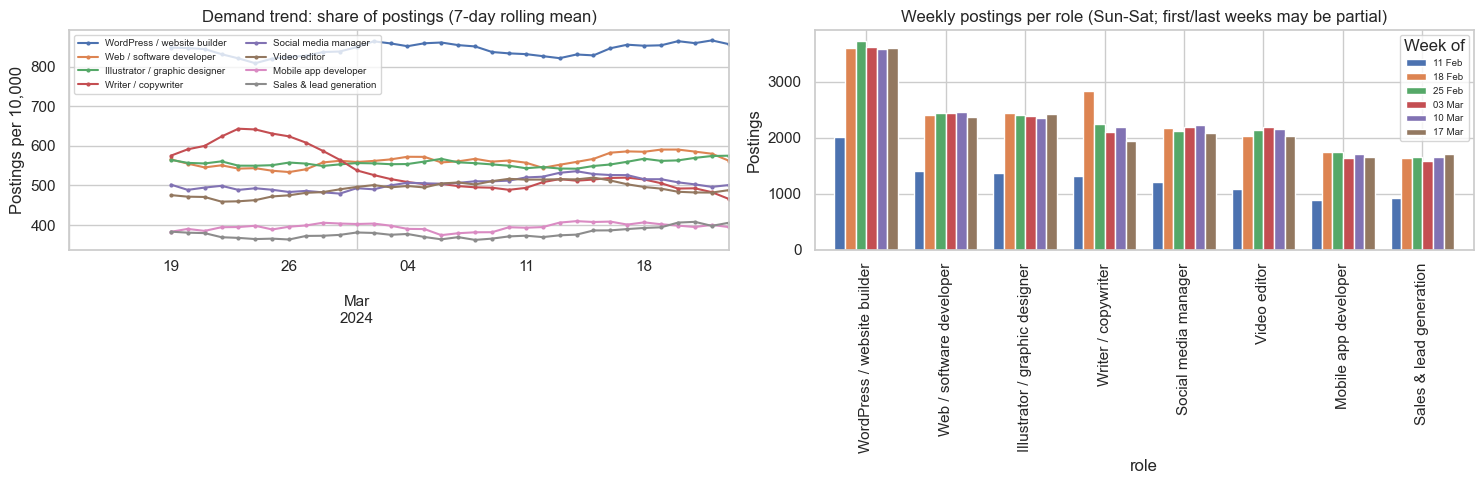

In [16]:
days = pd.date_range("2024-02-13", "2024-03-23")
roles = sorted(r for r in d3["role"].unique() if r != "Other")

# T = ALL postings per day (denominator); N = postings per role per day
T = d3.groupby("date").size().reindex(days)
N = (d3[d3["role"] != "Other"].groupby(["role", "date"]).size()
       .unstack(fill_value=0).reindex(index=roles, columns=days, fill_value=0))
# 15 Feb collection gap, unlike raw counts.
S = N / T * 1e4

top8 = N.sum(axis=1).nlargest(8).index
roll = S.loc[top8].T.rolling(7, min_periods=7).mean()   # 7-day mean removes weekday effects

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
roll.plot(ax=axes[0], marker="o", ms=2)
axes[0].set_title("Demand trend: share of postings (7-day rolling mean)")
axes[0].set_ylabel("Postings per 10,000"); axes[0].legend(fontsize=7, ncol=2)

weekly = N.T.groupby(N.columns.to_series().dt.to_period("W-SAT")).sum().T  # Sun-Sat weeks
weekly = weekly.loc[top8]
weekly.columns = [f"{c.start_time:%d %b}" for c in weekly.columns]
weekly.plot.bar(ax=axes[1], width=0.8)
axes[1].set_title("Weekly postings per role (Sun-Sat; first/last weeks may be partial)")
axes[1].set_ylabel("Postings"); axes[1].legend(fontsize=7, title="Week of")
plt.tight_layout(); plt.show()


### 3C. Forecasting model and backtest

In [17]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from scipy.stats import spearmanr

FIRST = days[0]
S_arr = {r: S.loc[r].values for r in roles}
N_arr = {r: N.loc[r].values for r in roles}
T_arr = T.values

def make_row(r, i, with_target=True):
    """Features for role r on day index i, using ONLY data from >= 7 days earlier
    (so the model really forecasts a week ahead)."""
    s = S_arr[r]
    row = {"role": r, "day": FIRST + pd.Timedelta(days=i),
           "lag7": s[i - 7],                 # same weekday, last week
           "m7": s[i - 13:i - 6].mean(),     # average share of the 7 days ending at t-7
           "That": T_arr[i - 7]}             # total postings forecast = same weekday last week
    if with_target:
        row["y"] = s[i]; row["n"] = N_arr[r][i]
    return row

D = pd.DataFrame([make_row(r, i) for r in roles for i in range(13, len(days))])

def design(frame):
    X = pd.DataFrame({"l_lag7": np.log1p(frame["lag7"]), "l_m7": np.log1p(frame["m7"])}, index=frame.index)
    for k in range(7):
        X[f"wd_{k}"] = (frame["day"].dt.weekday == k).astype(float)
    return X

def fit_predict(train, test):
    """Predicted share (per 10k) for each model."""
    Xtr, Xte, ytr = design(train), design(test), np.log1p(train["y"])
    ridge = Ridge(alpha=1.0).fit(Xtr, ytr)
    gbm = GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                    subsample=0.8, random_state=0).fit(Xtr, ytr)
    out = {"naive (same day last week)": test["lag7"].values,
           "mean of previous week": test["m7"].values,
           "ridge": np.expm1(ridge.predict(Xte)),
           "gbm": np.expm1(gbm.predict(Xte))}
    out["ensemble (mean, ridge, gbm)"] = (out["mean of previous week"] + out["ridge"] + out["gbm"]) / 3
    return out

# Rolling-origin backtest: forecast each of the last two Sun-Sat weeks, training only on the past
FOLDS = [("2024-03-10", "2024-03-16"), ("2024-03-17", "2024-03-23")]
results, bt_pairs = [], []
for start, end in FOLDS:
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    train, test = D[D["day"] < start], D[(D["day"] >= start) & (D["day"] <= end)].copy()
    for name, share in fit_predict(train, test).items():
        test["pred"] = np.clip(share, 0, None) / 1e4 * test["That"]       # share -> postings
        wk = test.groupby("role")[["pred", "n"]].sum()                      # weekly per role
        k = round(0.25 * len(wk))
        top_actual, top_pred = set(wk["n"].nlargest(k).index), set(wk["pred"].nlargest(k).index)
        results.append({"fold (week starting)": start.date(), "model": name,
                        "weekly_WAPE": (wk["pred"] - wk["n"]).abs().sum() / wk["n"].sum(),
                        "median_role_MAPE": ((wk["pred"] - wk["n"]).abs() / wk["n"]).median(),
                        "rank_spearman": spearmanr(wk["pred"], wk["n"])[0],
                        f"top25%_hit_rate": len(top_actual & top_pred) / k})
        bt_pairs.append(wk.assign(model=name, fold=start.date()).reset_index())

bt = pd.DataFrame(results)
bt_pairs = pd.concat(bt_pairs)
summary = bt.groupby("model")[["weekly_WAPE", "median_role_MAPE", "rank_spearman", "top25%_hit_rate"]].mean()
print("Per-fold results:"); display(bt.round(3))
print("Average over both folds (lower WAPE/MAPE is better):"); display(summary.sort_values("weekly_WAPE").round(3))


Per-fold results:


,fold (week starting),model,weekly_WAPE,median_role_MAPE,rank_spearman,top25%_hit_rate
0,2024-03-10,naive (same day last week),0.040,0.039,0.988,1.0
1,2024-03-10,mean of previous week,0.038,0.032,0.988,1.0
2,2024-03-10,ridge,0.054,0.057,0.987,1.0
3,2024-03-10,gbm,0.048,0.046,0.986,1.0
4,2024-03-10,"ensemble (mean, ridge, gbm)",0.040,0.044,0.987,1.0
5,2024-03-17,naive (same day last week),0.055,0.047,0.990,1.0
6,2024-03-17,mean of previous week,0.057,0.056,0.987,1.0
7,2024-03-17,ridge,0.053,0.053,0.987,1.0
8,2024-03-17,gbm,0.050,0.040,0.989,1.0
9,2024-03-17,"ensemble (mean, ridge, gbm)",0.053,0.044,0.987,1.0


Average over both folds (lower WAPE/MAPE is better):


,weekly_WAPE,median_role_MAPE,rank_spearman,top25%_hit_rate
model,,,,
"ensemble (mean, ridge, gbm)",0.046,0.044,0.987,1.0
naive (same day last week),0.047,0.043,0.989,1.0
mean of previous week,0.048,0.044,0.988,1.0
gbm,0.049,0.043,0.987,1.0
ridge,0.053,0.055,0.987,1.0


### 3D. Is growth predictable? Final forecast

Spearman between consecutive weekly growth rates (across roles):
  week1->2 vs week2->3: -0.21
  week2->3 vs week3->4: -0.52

Best model by average weekly WAPE: ensemble (mean, ridge, gbm)
80% interval multiplier from backtest: x0.90 to x1.06


,last_week_postings,forecast_postings,low_80,high_80,change_vs_last_week_pct,rank,high_demand
role,,,,,,,
WordPress / website builder,3602,3521.0,3169.0,3740.0,-2.2,1,True
Web / software developer,2374,2379.0,2141.0,2527.0,0.2,2,True
Illustrator / graphic designer,2422,2352.0,2117.0,2498.0,-2.9,3,True
Social media manager,2090,2102.0,1891.0,2232.0,0.6,4,True
Video editor,2029,2045.0,1840.0,2172.0,0.8,5,True
Writer / copywriter,1947,2037.0,1833.0,2164.0,4.6,6,True
Sales & lead generation,1712,1677.0,1509.0,1781.0,-2.0,7,True
Mobile app developer,1656,1669.0,1502.0,1772.0,0.8,8,True
Virtual assistant,1198,1225.0,1103.0,1301.0,2.3,9,True


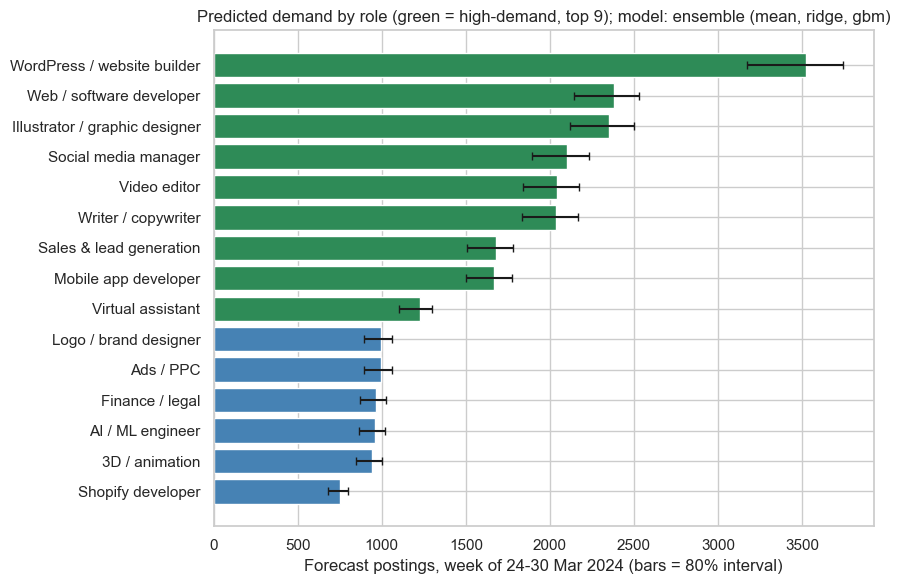

Saved: task3_demand_forecast.csv, task3_backtest_metrics.csv


In [18]:
# --- Does growth persist? (can we predict WHICH roles will grow?) ---
full_weeks = pd.to_datetime(["2024-02-19", "2024-02-26", "2024-03-04", "2024-03-11"])
Nw = pd.concat([N[pd.date_range(w, periods=7)].sum(axis=1) for w in full_weeks], axis=1)
Tw = np.array([T[pd.date_range(w, periods=7)].sum() for w in full_weeks])
Sw = Nw.values / Tw
g = np.log(Sw[:, 1:] / Sw[:, :-1])          # weekly log growth of each role's share
print("Spearman between consecutive weekly growth rates (across roles):")
print(f"  week1->2 vs week2->3: {spearmanr(g[:, 0], g[:, 1])[0]:+.2f}")
print(f"  week2->3 vs week3->4: {spearmanr(g[:, 1], g[:, 2])[0]:+.2f}")

best = summary["weekly_WAPE"].idxmin()
print(f"\nBest model by average weekly WAPE: {best}")

future = pd.DataFrame([make_row(r, len(days) + k, with_target=False) for r in roles for k in range(7)])
fc = fit_predict(D, future)[best]
future["pred_posts"] = np.clip(fc, 0, None) / 1e4 * future["That"]
fc_week = future.groupby("role")["pred_posts"].sum()

pairs = bt_pairs[bt_pairs["model"] == best]
ratio = (pairs["n"] / pairs["pred"]).values
q10, q90 = np.quantile(ratio, [0.10, 0.90])

last_week = N[pd.date_range("2024-03-17", periods=7)].sum(axis=1)
forecast = pd.DataFrame({"last_week_postings": last_week,
                         "forecast_postings": fc_week.round(0),
                         "low_80": (fc_week * q10).round(0),
                         "high_80": (fc_week * q90).round(0)})
forecast["change_vs_last_week_pct"] = ((forecast["forecast_postings"] / forecast["last_week_postings"] - 1) * 100).round(1)
forecast = forecast.sort_values("forecast_postings", ascending=False)
forecast["rank"] = range(1, len(forecast) + 1)
k_hi = round(0.25 * len(forecast))
forecast["high_demand"] = forecast["rank"] <= k_hi
print(f"80% interval multiplier from backtest: x{q10:.2f} to x{q90:.2f}")
display(forecast)

top = forecast.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
err = np.vstack([top["forecast_postings"] - top["low_80"], top["high_80"] - top["forecast_postings"]])
ax.barh(top.index, top["forecast_postings"], xerr=err, capsize=3,
        color=np.where(top["high_demand"], "seagreen", "steelblue"))
ax.set_xlabel("Forecast postings, week of 24-30 Mar 2024 (bars = 80% interval)")
ax.set_title(f"Predicted demand by role (green = high-demand, top {k_hi}); model: {best}")
plt.tight_layout(); plt.show()

forecast.to_csv("task3_demand_forecast.csv")
summary.to_csv("task3_backtest_metrics.csv")
print("Saved: task3_demand_forecast.csv, task3_backtest_metrics.csv")


## Compare average hourly rates across countries


In [19]:
import plotly.graph_objects as go
from scipy.stats import kruskal

MIN_N = 30   # countries with fewer rated postings are too noisy to compare

# df = cleaned data from Step 2 (hourly_mid already has the top-1% outliers removed).
# NOTE: the CSV does not state the currency (assumed USD) or whether 'country' is the
# client's or the freelancer's location (on Upwork it is most likely the client's).
rate = df[df["is_hourly"] & df["hourly_mid"].notna() & (df["country"] != "Unknown")].copy()
print(f"Hourly postings with a rate and a country: {len(rate):,}")

g = rate.groupby("country")
country_stats = pd.DataFrame({
    "n": g.size(),
    "mean_rate": g["hourly_mid"].mean(),
    "median_rate": g["hourly_mid"].median(),
    "avg_low": g["hourly_low"].mean(),
    "avg_high": g["hourly_high"].mean(),
    "sem": g["hourly_mid"].sem(),
})
country_stats["ci95"] = 1.96 * country_stats["sem"]          # approx. 95% CI half-width
print(f"Countries in data: {len(country_stats)}")
country_stats = country_stats[country_stats["n"] >= MIN_N].sort_values("mean_rate", ascending=False)
print(f"Countries with at least {MIN_N} rated postings: {len(country_stats)} "
      f"(covering {country_stats['n'].sum() / len(rate):.1%} of rated postings)")
country_stats.round(2).head(15)


Hourly postings with a rate and a country: 99,263
Countries in data: 191
Countries with at least 30 rated postings: 93 (covering 99.3% of rated postings)


,n,mean_rate,median_rate,avg_low,avg_high,sem,ci95
country,,,,,,,
Thailand,277,35.19,22.5,13.96,57.61,2.02,3.96
Latvia,111,31.71,30.0,17.94,46.81,1.83,3.59
Oman,48,30.21,29.5,18.19,42.23,2.04,3.99
Kenya,367,30.14,26.0,21.51,41.13,0.95,1.87
Ukraine,576,29.97,25.0,18.32,41.93,0.83,1.62
Vietnam,253,29.92,27.5,14.84,45.59,1.24,2.42
United States,47555,29.83,25.0,18.70,41.82,0.10,0.20
Colombia,248,28.61,22.5,16.59,41.80,1.43,2.80
Bosnia and Herzegovina,39,28.33,25.0,13.41,44.38,3.90,7.64


### 4A. Interactive map

In [20]:
# ISO-3 codes for plotly (explicit mapping, no extra library needed)
ISO3 = {
 "Albania":"ALB","Algeria":"DZA","Argentina":"ARG","Armenia":"ARM","Australia":"AUS","Austria":"AUT",
 "Bahrain":"BHR","Bangladesh":"BGD","Belgium":"BEL","Bosnia and Herzegovina":"BIH","Brazil":"BRA",
 "Bulgaria":"BGR","Canada":"CAN","Chile":"CHL","China":"CHN","Colombia":"COL","Costa Rica":"CRI",
 "Croatia":"HRV","Cyprus":"CYP","Czech Republic":"CZE","Denmark":"DNK","Dominican Republic":"DOM",
 "Ecuador":"ECU","Egypt":"EGY","Estonia":"EST","Ethiopia":"ETH","Finland":"FIN","France":"FRA",
 "Georgia":"GEO","Germany":"DEU","Greece":"GRC","Hong Kong":"HKG","Hungary":"HUN","India":"IND",
 "Indonesia":"IDN","Ireland":"IRL","Israel":"ISR","Italy":"ITA","Jamaica":"JAM","Japan":"JPN",
 "Jordan":"JOR","Kenya":"KEN","Kuwait":"KWT","Latvia":"LVA","Lebanon":"LBN","Lithuania":"LTU",
 "Luxembourg":"LUX","Macedonia":"MKD","Malaysia":"MYS","Malta":"MLT","Mauritius":"MUS","Mexico":"MEX",
 "Moldova":"MDA","Montenegro":"MNE","Morocco":"MAR","Nepal":"NPL","Netherlands":"NLD","New Zealand":"NZL",
 "Nigeria":"NGA","Norway":"NOR","Oman":"OMN","Pakistan":"PAK","Panama":"PAN","Peru":"PER",
 "Philippines":"PHL","Poland":"POL","Portugal":"PRT","Puerto Rico":"PRI","Qatar":"QAT","Romania":"ROU",
 "Saudi Arabia":"SAU","Serbia":"SRB","Singapore":"SGP","Slovakia":"SVK","Slovenia":"SVN",
 "South Africa":"ZAF","South Korea":"KOR","Spain":"ESP","Sri Lanka":"LKA","Sweden":"SWE",
 "Switzerland":"CHE","Taiwan":"TWN","Thailand":"THA","Tunisia":"TUN","Turkey":"TUR","Ukraine":"UKR",
 "United Arab Emirates":"ARE","United Kingdom":"GBR","United States":"USA","Uruguay":"URY",
 "Uzbekistan":"UZB","Venezuela":"VEN","Vietnam":"VNM",
}
country_stats["iso3"] = country_stats.index.map(ISO3)
missing = country_stats[country_stats["iso3"].isna()].index.tolist()
if missing:
    print("No ISO code (not shown on the map):", missing)
m = country_stats.dropna(subset=["iso3"])

hover = (m.index + "<br>Postings with rate: " + m["n"].astype(str)
         + "<br>Mean: $" + m["mean_rate"].round(2).astype(str) + "/h"
         + "<br>Median: $" + m["median_rate"].round(2).astype(str) + "/h"
         + "<br>Avg range: $" + m["avg_low"].round(1).astype(str) + " - $" + m["avg_high"].round(1).astype(str))

def zrange(v):                       # clip colour scale so a few extreme countries don't wash out the rest
    return float(np.quantile(v, 0.05)), float(np.quantile(v, 0.95))

fig = go.Figure(go.Choropleth(
    locations=m["iso3"], z=m["mean_rate"], text=hover, hoverinfo="text",
    colorscale="Viridis", zmin=zrange(m["mean_rate"])[0], zmax=zrange(m["mean_rate"])[1],
    colorbar=dict(title="USD/h<br>(assumed)"), marker_line_width=0.3))

buttons = []
for label, col in [("Mean rate", "mean_rate"), ("Median rate", "median_rate")]:
    lo, hi = zrange(m[col])
    buttons.append(dict(label=label, method="restyle",
                        args=[{"z": [m[col].tolist()], "zmin": [lo], "zmax": [hi]}]))
fig.update_layout(
    title=f"Average hourly rate offered by client country (countries with at least {MIN_N} rated postings)",
    updatemenus=[dict(type="buttons", direction="right", x=0.0, y=1.12, buttons=buttons)],
    geo=dict(showframe=False, showcoastlines=False, projection_type="natural earth"),
    margin=dict(l=0, r=0, t=70, b=0), height=520)
fig.write_html("task4_hourly_rate_map.html")
fig.show()


### 4B. Highest and lowest countries

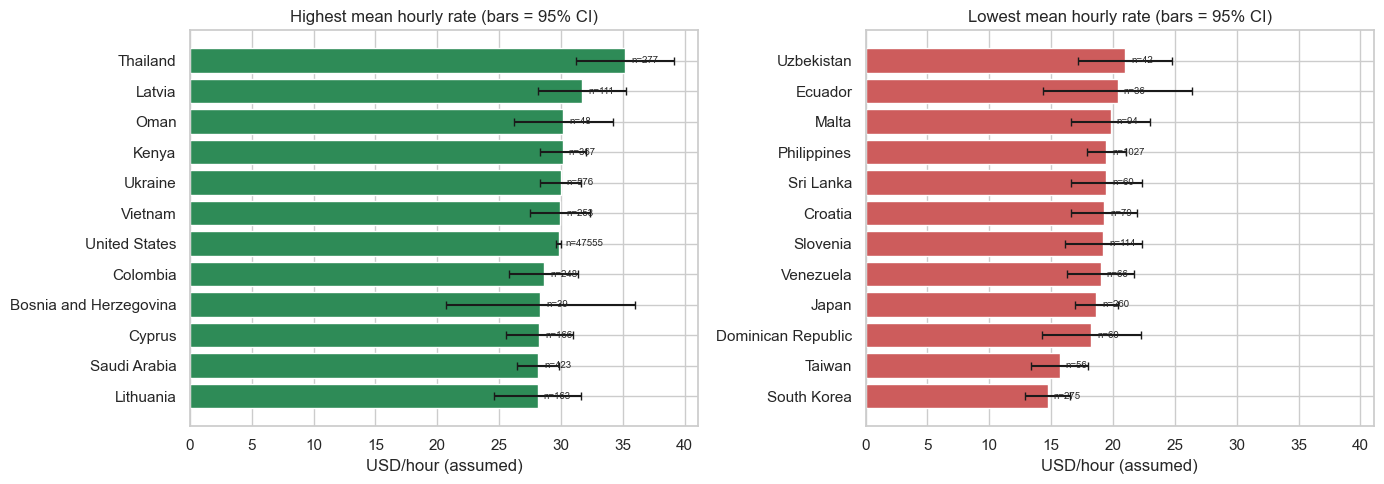

Kruskal-Wallis across 93 countries: H = 2533, p < 1e-300
United States mean: $29.83/h | median of country means: $24.53/h
Spread of country means: $14.72 to $35.19


In [21]:
top = country_stats.head(12).iloc[::-1]
bot = country_stats.tail(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, data, title, col in [(axes[0], top, "Highest mean hourly rate", "seagreen"),
                             (axes[1], bot, "Lowest mean hourly rate", "indianred")]:
    ax.barh(data.index, data["mean_rate"], xerr=data["ci95"], color=col, capsize=3)
    for y, (n, v) in enumerate(zip(data["n"], data["mean_rate"])):
        ax.text(v + 0.5, y, f"n={n}", va="center", fontsize=7)
    ax.set_title(title + " (bars = 95% CI)"); ax.set_xlabel("USD/hour (assumed)")
plt.tight_layout(); plt.show()

groups = [rate.loc[rate["country"] == c, "hourly_mid"].values for c in country_stats.index]
H, p = kruskal(*groups)
p_txt = "p < 1e-300" if p == 0 else f"p = {p:.2g}"
print(f"Kruskal-Wallis across {len(groups)} countries: H = {H:.0f}, {p_txt}")
us = country_stats.loc["United States", "mean_rate"]
print(f"United States mean: ${us:.2f}/h | median of country means: ${country_stats['mean_rate'].median():.2f}/h")
print(f"Spread of country means: ${country_stats['mean_rate'].min():.2f} to ${country_stats['mean_rate'].max():.2f}")


### 4C. Role-adjusted comparison

In [22]:
from sklearn.linear_model import LinearRegression

adj = rate[rate["country"].isin(country_stats.index)].copy()
adj["role"] = adj["title_clean"].apply(assign_role)                 # taxonomy from Task 3
big = country_stats[country_stats["n"] >= 300].index                # enough data for its own coefficient
adj["country_grp"] = np.where(adj["country"].isin(big), adj["country"], "Other countries")

X = pd.get_dummies(adj[["role", "country_grp"]]).astype(float)
X = X.drop(columns=["role_Other", "country_grp_United States"])      # baselines: 'Other' role, United States
y = np.log(adj["hourly_mid"])
lm = LinearRegression().fit(X, y)
print(f"R2 with role + country: {lm.score(X, y):.3f}  (rows: {len(adj):,})")

coef = pd.Series(lm.coef_, index=X.columns)
c = coef[coef.index.str.startswith("country_grp_")]
c.index = c.index.str.replace("country_grp_", "", regex=False)
adjusted = (np.exp(c) - 1) * 100                                    # % difference vs United States, same role

raw = (country_stats["mean_rate"] / us - 1) * 100                   # % difference vs United States, raw
cmp_df = pd.DataFrame({"n": country_stats["n"], "raw_diff_vs_US_pct": raw,
                       "role_adjusted_diff_vs_US_pct": adjusted}).dropna()
cmp_df.sort_values("role_adjusted_diff_vs_US_pct").round(1)


R2 with role + country: 0.171  (rows: 98,572)


,n,raw_diff_vs_US_pct,role_adjusted_diff_vs_US_pct
Philippines,1027.0,-34.7,-38.5
India,4406.0,-27.6,-27.1
Netherlands,1605.0,-26.8,-23.0
Pakistan,1429.0,-26.0,-23.0
Bangladesh,721.0,-24.7,-20.3
China,413.0,-24.1,-20.1
Israel,808.0,-16.4,-18.3
United Arab Emirates,1284.0,-18.0,-17.6
France,1254.0,-17.8,-17.1
Australia,5879.0,-20.5,-17.0


In [23]:
country_stats.drop(columns=["sem"]).round(3).to_csv("task4_country_hourly_rates.csv")
print("Saved: task4_country_hourly_rates.csv, task4_hourly_rate_map.html (open the HTML in any browser)")


Saved: task4_country_hourly_rates.csv, task4_hourly_rate_map.html (open the HTML in any browser)


## Job recommendation engine (prototype and Streamlit app)
**Approach**
 the engine is `recommender_app/recommender.py` and the user interface is a **Streamlit app** (`recommender_app/streamlit_app.py`). The function interface is documented in `recommender_app/README.md`.


*Keep the `recommender_app` folder next to this notebook.*

### 5A. Build the index

In [24]:
import sys
sys.path.insert(0, "recommender_app")      # folder with recommender.py, roles.py, app.py (next to this notebook)

from recommender import JobRecommender
from roles import assign_role as app_assign_role

rec = JobRecommender(RAW)                  # builds the TF-IDF index (about 10 seconds)
meta = rec.meta()
print("Date range:", meta["date_range"][0][:10], "->", meta["date_range"][1][:10])
print(f"Hourly share: {meta['hourly_share']:.1%} | countries: {len(meta['countries'])}")


[recommender] 241,588 postings, 197,630 unique titles, 431,503 terms, ready in 12.9s
Date range: 2024-02-12 -> 2024-03-24
Hourly share: 57.5% | countries: 213


### 5B. Example recommendations

In [25]:
import time

def show(results, n=6):
    cols = ["title", "role", "job_type", "hourly_low", "hourly_high", "budget", "country", "score", "similar_postings"]
    return pd.DataFrame(results)[cols].head(n)

demos = [
    ("react node js developer", {}),
    ("video editor youtube shorts", {"job_type": "hourly", "min_hourly": 25}),
    ("python data scraping", {"countries": ["United States"]}),
]
for query, filters in demos:
    t0 = time.time()
    out = rec.recommend(query, top_n=6, **filters)
    print(f"Query: {query!r}  filters: {filters or 'none'}  ({(time.time() - t0) * 1000:.0f} ms)")
    display(show(out))


Query: 'react node js developer'  filters: none  (45 ms)


,title,role,job_type,hourly_low,hourly_high,budget,country,score,similar_postings
0,React Node JS Developer,Web / software developer,fixed,NaN,NaN,400.0,Pakistan,1.0000,3
1,React / Node.JS,Web / software developer,fixed,NaN,NaN,400.0,Belgium,0.8783,1
2,"Need React, Node.js developer",Web / software developer,hourly,50.0,70.0,NaN,Pakistan,0.8671,1
3,Experienced React/Node.js Developer,Web / software developer,hourly,20.0,30.0,NaN,United States,0.8528,1
4,Senior React/Node.js Developer,Web / software developer,hourly,70.0,85.0,NaN,United States,0.8513,1
5,Node.js Developer,Web / software developer,hourly,10.0,25.0,NaN,United States,0.8102,12


Query: 'video editor youtube shorts'  filters: {'job_type': 'hourly', 'min_hourly': 25}  (34 ms)


,title,role,job_type,hourly_low,hourly_high,budget,country,score,similar_postings
0,Video editor for YouTube shorts,Video editor,hourly,10.0,30.0,None,New Zealand,1.0000,1
1,TikTok Video Editor for YouTube Shorts,Social media manager,hourly,10.0,30.0,None,United Kingdom,0.8471,1
2,Youtube Shorts,Other,hourly,10.0,30.0,None,India,0.7406,1
3,Video Editor for YouTube,Video editor,hourly,10.0,40.0,None,United States,0.7307,7
4,Video Editor (YouTube),Video editor,hourly,10.0,30.0,None,United States,0.7307,2
5,Video editor for youtube shorts / tiktok content,Social media manager,hourly,20.0,39.0,None,United States,0.7260,1


Query: 'python data scraping'  filters: {'countries': ['United States']}  (48 ms)


,title,role,job_type,hourly_low,hourly_high,budget,country,score,similar_postings
0,Data Scraping,Data analyst / scientist,hourly,NaN,NaN,NaN,United States,0.7091,12
1,Python Data Analysis,Data analyst / scientist,fixed,NaN,NaN,200.0,United States,0.5923,1
2,Python Data Scraper,Data analyst / scientist,hourly,4.0,15.0,NaN,United States,0.5535,1
3,Website Data Scraping,Data analyst / scientist,hourly,3.0,10.0,NaN,United States,0.5265,1
4,Data Scraping Specialist,Data analyst / scientist,hourly,NaN,NaN,NaN,United States,0.5079,1
5,Web data scraping.,Data analyst / scientist,hourly,8.0,25.0,NaN,United States,0.5057,1


### 5C. Offline evaluation

In [26]:
from functools import lru_cache
from sklearn.feature_extraction.text import TfidfVectorizer


K, N_QUERIES = 10, 800
rng = np.random.default_rng(42)

@lru_cache(maxsize=None)
def role_of(i):
    return app_assign_role(rec.titles[i])

pool = rng.choice(len(rec.titles), size=4000, replace=False)
queries = [i for i in pool if role_of(i) != "Other"][:N_QUERIES]
print(f"Evaluation queries: {len(queries)} (random titles with a named role)")

def evaluate(X):
    hits, returned = [], []
    for qi in queries:
        sims = (X @ X[qi].T).toarray().ravel()
        sims[qi] = -1
        top = np.argpartition(-sims, K)[:K]
        top = top[sims[top] > 0]                                   # drop zero-similarity filler
        returned.append(len(top))
        hits.extend(role_of(t) == role_of(qi) for t in top)
    return np.mean(hits), np.mean(returned)

# Baseline: 10 random titles per query
rand_hits = [role_of(t) == role_of(qi) for qi in queries for t in rng.choice(len(rec.titles), K)]

uni = TfidfVectorizer(ngram_range=(1, 1), sublinear_tf=True, stop_words=rec.vectorizer.stop_words,
                      token_pattern=r"(?u)[a-z0-9+#]+", lowercase=False, dtype=np.float32)
X_uni = uni.fit_transform(rec.titles)

rows = []
for name, X in [("TF-IDF words only", X_uni), ("TF-IDF words + word pairs (shipped)", rec.X)]:
    p, avg_n = evaluate(X)
    rows.append({"model": name, f"precision@{K} (same role)": p, "avg results returned": avg_n})
rows.append({"model": "Random titles (baseline)", f"precision@{K} (same role)": np.mean(rand_hits), "avg results returned": K})
pd.DataFrame(rows).round(3)


Evaluation queries: 800 (random titles with a named role)


,model,precision@10 (same role),avg results returned
0,TF-IDF words only,0.551,10.0
1,TF-IDF words + word pairs (shipped),0.572,10.0
2,Random titles (baseline),0.035,10.0


### 5D. The function interface used by the app

In [27]:
import json

# The Streamlit page calls exactly this function; no web server is needed to use it from Python.
out = rec.recommend("python data scraping", top_n=2, job_type="hourly", min_hourly=20)
print(json.dumps(out, indent=2)[:1500])

try:
    rec.recommend("dev", top_n=999)
except ValueError as e:
    print("\nInvalid input is rejected with ValueError:", e)


[
  {
    "title": "Data Scraping",
    "role": "Data analyst / scientist",
    "job_type": "hourly",
    "hourly_low": 7.0,
    "hourly_high": 20.0,
    "budget": null,
    "country": "United Kingdom",
    "posted_at": "2024-02-26T11:21:46+00:00",
    "link": "https://www.upwork.com/jobs/Data-Scraping_%7E013f7b595545d57a29?source=rss",
    "score": 0.7091,
    "matched_terms": [
      "data",
      "scraping"
    ],
    "similar_postings": 2
  },
  {
    "title": "Python data engineer",
    "role": "Data analyst / scientist",
    "job_type": "hourly",
    "hourly_low": 15.0,
    "hourly_high": 25.0,
    "budget": null,
    "country": "Italy",
    "posted_at": "2024-02-29T16:01:18+00:00",
    "link": "https://www.upwork.com/jobs/Python-data-engineer_%7E01b99923d3f2771959?source=rss",
    "score": 0.5913,
    "matched_terms": [
      "data",
      "python"
    ],
    "similar_postings": 1
  }
]

Invalid input is rejected with ValueError: top_n must be an integer between 1 and 100


**Run the Streamlit app** (in a terminal, from the project folder):
```
cd recommender_app
pip install -r requirements.txt
streamlit run streamlit_app.py
```
Your browser opens at http://localhost:8501. 

## Track changes in job market dynamics (dashboard)
 The **Streamlit dashboard** (`job_market_dashboard/dashboard.py`) shows KPIs, trends, role movers, geography and work signals, weekly or monthly. A new monthly CSV dropped in its `data` folder is picked up and combined with the old data.

*Keep the `job_market_dashboard` folder next to this notebook.*

In [28]:
sys.path.insert(0, "job_market_dashboard")      
import market_metrics as mm

jobs = mm.load_jobs([RAW])                      
daily = jobs.attrs["daily"]
excluded = daily[daily["active"] & ~daily["complete"]].index.strftime("%a %d %b").tolist()
print(f"Complete days used: {int(daily['complete'].sum())} | partial days excluded: {excluded}")
print(f"Sparse straggler days ignored (before the real collection period): {int((~daily['active']).sum())}")

weekly = mm.period_metrics(jobs, "week")
monthly = mm.period_metrics(jobs, "month")
SHOW = ["days_covered", "postings_per_day", "hourly_share_pct", "mean_hourly_rate", "mean_fixed_budget",
        "us_share_pct", "countries", "remote_per10k", "ai_ml_share_pct", "is_full_period"]
print("\nWEEKLY (weeks run Sunday-Saturday; is_full_period = False means a partial week)")
display(weekly[SHOW].round(2))
print("MONTHLY (per-day averages; both months are partial in this data, so compare with care)")
display(monthly[SHOW].round(2))

full = weekly[weekly["is_full_period"]]
print(f"Full weeks available for trend analysis: {len(full)}")


Complete days used: 39 | partial days excluded: ['Thu 15 Feb', 'Sun 24 Mar']
Sparse straggler days ignored (before the real collection period): 48

WEEKLY (weeks run Sunday-Saturday; is_full_period = False means a partial week)


,days_covered,postings_per_day,hourly_share_pct,mean_hourly_rate,mean_fixed_budget,us_share_pct,countries,remote_per10k,ai_ml_share_pct,is_full_period
period,,,,,,,,,,
2024-02-11,4,5531.25,58.65,27.24,380.63,41.34,157,53.79,2.25,False
2024-02-18,7,6360.86,58.53,26.83,415.42,39.77,177,59.29,2.02,True
2024-02-25,7,6181.29,57.15,27.75,391.61,41.92,177,51.08,2.28,True
2024-03-03,7,6170.71,57.74,27.39,383.22,41.44,176,54.40,2.32,True
2024-03-10,7,6070.00,56.64,27.01,405.43,40.56,175,53.42,2.34,True
2024-03-17,7,6002.00,57.05,27.25,373.83,40.72,181,59.98,2.26,True


MONTHLY (per-day averages; both months are partial in this data, so compare with care)


,days_covered,postings_per_day,hourly_share_pct,mean_hourly_rate,mean_fixed_budget,us_share_pct,countries,remote_per10k,ai_ml_share_pct,is_full_period
period,,,,,,,,,,
2024-02-01,16,6170.81,58.27,27.22,402.25,40.78,198,54.90,2.15,False
2024-03-01,23,6038.52,57.04,27.25,386.27,41.02,200,55.87,2.31,False


Full weeks available for trend analysis: 5


Full weeks available for trend analysis: 5


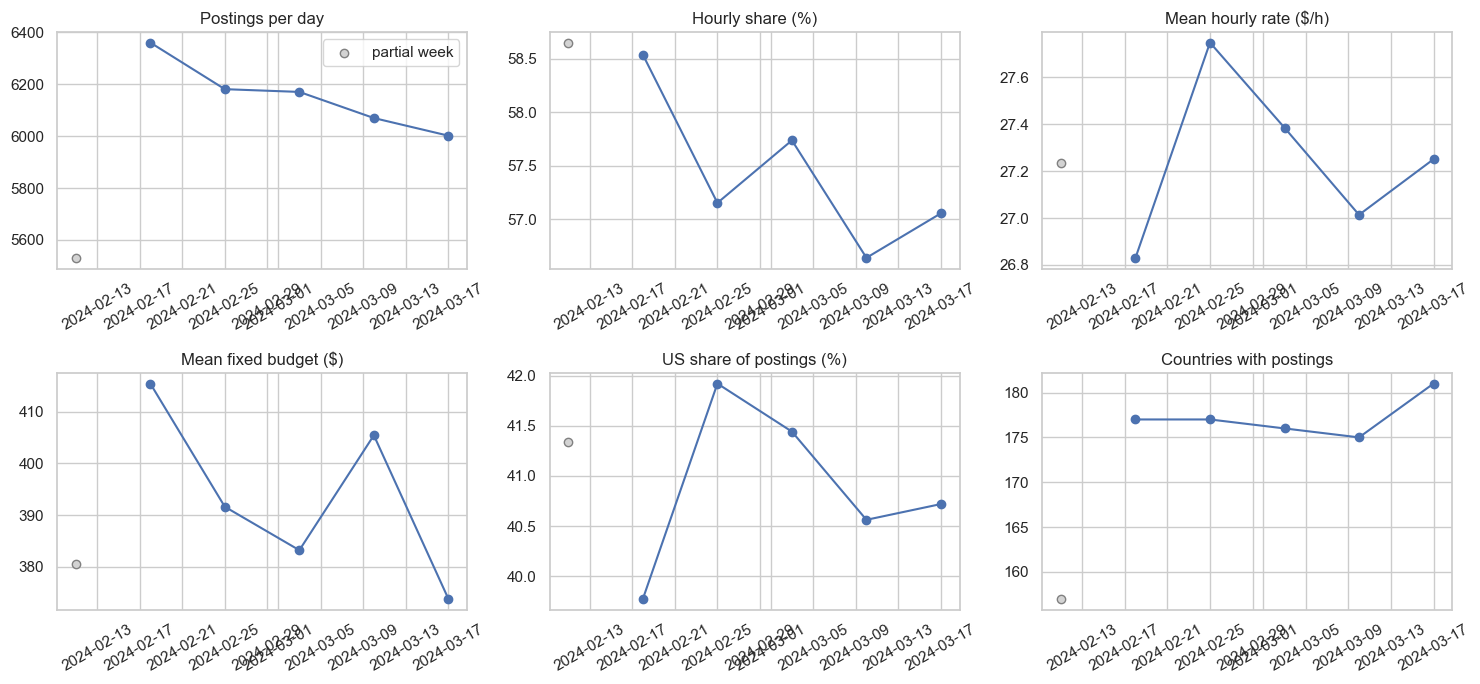

Latest full week starts 17 Mar 2024


,latest full week,previous week,average of earlier weeks,vs previous (%),vs earlier average (%)
postings_per_day,6002.0,6070.0,6195.71,-1.120264,-3.126585
hourly_share_pct,57.054791,56.639209,57.52,0.733736,-0.800658
mean_hourly_rate,27.250925,27.013615,27.24,0.878482,0.023847
mean_fixed_budget,373.825759,405.42939,398.92,-7.795101,-6.290552
us_share_pct,40.71976,40.562485,40.93,0.387735,-0.501967
countries,181,175,176.25,3.428571,2.695035
remote_per10k,59.980007,53.424335,54.55,12.270946,9.956295
ai_ml_share_pct,2.263531,2.344081,2.24,-3.436304,1.059271


Role share of postings: latest full week vs earlier weeks (top 10 roles; see Task 2 for significance tests)


,latest %,earlier average %,change (pp)
role,,,
Sales & lead generation,4.07,3.77,0.30
Illustrator / graphic designer,5.76,5.54,0.22
WordPress / website builder,8.57,8.40,0.17
Web / software developer,5.65,5.64,0.01
Mobile app developer,3.94,3.95,-0.01
Logo / brand designer,2.38,2.42,-0.05
Social media manager,4.97,5.04,-0.06
Video editor,4.83,4.93,-0.10
Virtual assistant,2.85,3.11,-0.26


In [29]:
part = weekly[~weekly["is_full_period"]]
panels = [("postings_per_day", "Postings per day"), ("hourly_share_pct", "Hourly share (%)"),
          ("mean_hourly_rate", "Mean hourly rate ($/h)"), ("mean_fixed_budget", "Mean fixed budget ($)"),
          ("us_share_pct", "US share of postings (%)"), ("countries", "Countries with postings")]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (col, title) in zip(axes.ravel(), panels):
    ax.plot(full.index, full[col], marker="o")
    ax.scatter(part.index, part[col], color="lightgray", edgecolor="gray", zorder=3, label="partial week")
    ax.set_title(title); ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

metrics = ["postings_per_day", "hourly_share_pct", "mean_hourly_rate", "mean_fixed_budget",
           "us_share_pct", "countries", "remote_per10k", "ai_ml_share_pct"]
latest, previous, earlier = full.iloc[-1][metrics], full.iloc[-2][metrics], full.iloc[:-1].mean()[metrics]
changes = pd.DataFrame({"latest full week": latest, "previous week": previous, "average of earlier weeks": earlier})
changes["vs previous (%)"] = (latest / previous - 1) * 100
changes["vs earlier average (%)"] = (latest / earlier - 1) * 100
print(f"Latest full week starts {full.index[-1]:%d %b %Y}")
display(changes.round(2))

shares = mm.role_share(jobs, "week")[full.index]
role_change = pd.DataFrame({"latest %": shares.iloc[:, -1], "earlier average %": shares.iloc[:, :-1].mean(axis=1)})
role_change["change (pp)"] = role_change["latest %"] - role_change["earlier average %"]
top_roles = shares.mean(axis=1).nlargest(10).index
print("Role share of postings: latest full week vs earlier weeks (top 10 roles; see Task 2 for significance tests)")
display(role_change.loc[top_roles].sort_values("change (pp)", ascending=False).round(2))


**Run the dashboard:**
```
cd job_market_dashboard
pip install -r requirements.txt
streamlit run dashboard.py
```
**Reading the tables:** the data has about 5 full weeks and no full month, so small changes are mostly noise. The dashboard is a monitoring tool: it becomes more useful with every monthly export you add.

## Investigate trends in the remote work landscape


Postings analysed: 215,494 in 5 full weeks (42,014 to 44,526 per week)


,titles,share_%,mean_per10k,min_per10k,max_per10k,trend_%_per_week,p_same_rate,p_corrected,verdict
signal,,,,,,,,,
remote,1199,0.556,55.635,51.076,59.980,0.670,0.328,1.000,no detectable change
work from home,107,0.050,4.951,3.467,7.861,-6.151,0.008,0.068,no detectable change
long term / ongoing,2205,1.023,102.330,97.110,108.261,-0.298,0.419,1.000,no detectable change
full time,902,0.419,41.880,36.832,46.222,0.875,0.228,1.000,no detectable change
part time,928,0.431,43.031,41.653,46.490,-2.504,0.801,1.000,no detectable change
contract,920,0.427,42.713,37.902,47.459,2.444,0.153,1.000,no detectable change
urgent / asap,1764,0.819,81.831,79.503,86.242,-0.800,0.809,1.000,no detectable change
on-site / hybrid,298,0.138,13.833,10.355,15.947,0.142,0.150,1.000,no detectable change
location restricted,343,0.159,15.920,13.886,19.041,1.474,0.289,1.000,no detectable change


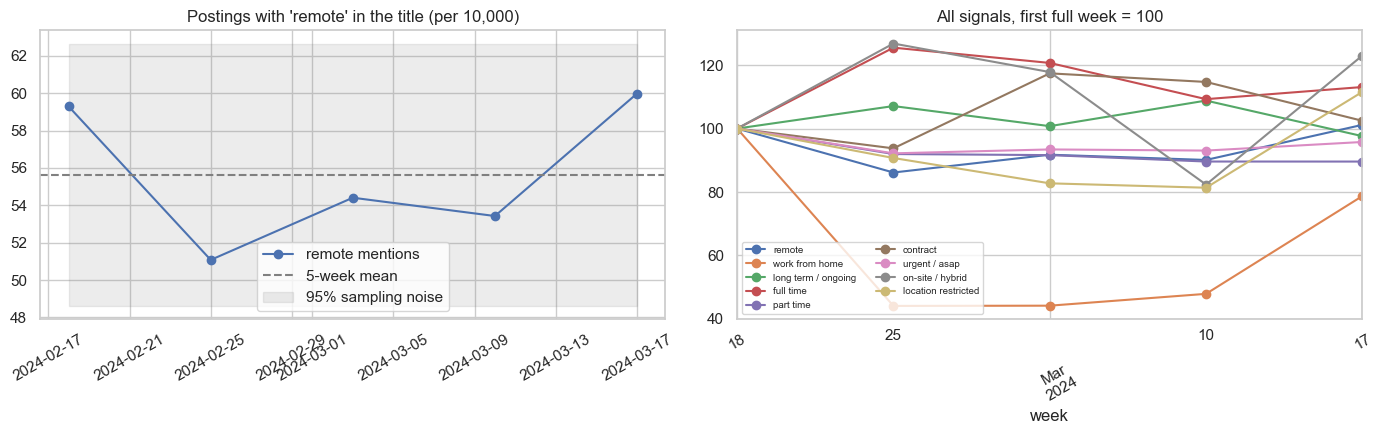

In [30]:
from scipy.stats import chi2_contingency, linregress, mannwhitneyu
from IPython.display import Markdown

# Complete days in FULL weeks only, so every week has the same 7 weekdays
d7 = jobs[jobs["day_complete"]].copy()
d7["week"] = mm.period_start(d7["date"], "week")
d7 = d7[d7["week"].isin(full.index)]
wk_n = d7.groupby("week").size()
print(f"Postings analysed: {len(d7):,} in {len(wk_n)} full weeks ({wk_n.min():,} to {wk_n.max():,} per week)")

weekly_per10k, rows = {}, []
for name, pat in mm.SIGNAL_PATTERNS.items():
    hit = d7["title_clean"].str.contains(pat.pattern, regex=True)
    counts = hit.groupby(d7["week"]).sum()
    per10k = counts / wk_n * 1e4
    weekly_per10k[name] = per10k
    p_same = chi2_contingency(np.vstack([counts.values, (wk_n - counts).values]))[1]   # is the rate the same every week?
    slope = linregress(range(len(per10k)), per10k.values).slope
    rows.append({"signal": name, "titles": int(counts.sum()), "share_%": counts.sum() / len(d7) * 100,
                 "mean_per10k": per10k.mean(), "min_per10k": per10k.min(), "max_per10k": per10k.max(),
                 "trend_%_per_week": slope / per10k.mean() * 100, "p_same_rate": p_same})
sig = pd.DataFrame(rows).set_index("signal")
sig["p_corrected"] = (sig["p_same_rate"] * len(sig)).clip(upper=1)          # Bonferroni over 9 signals
sig["verdict"] = np.where(sig["p_corrected"] < 0.05, "changed", "no detectable change")
display(sig.round(3))

per10k_df = pd.DataFrame(weekly_per10k)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
n_week, p0 = wk_n.mean(), per10k_df["remote"].mean() / 1e4
band = 1.96 * np.sqrt(p0 * (1 - p0) / n_week) * 1e4
axes[0].plot(per10k_df.index, per10k_df["remote"], marker="o", label="remote mentions")
axes[0].axhline(p0 * 1e4, color="gray", ls="--", label="5-week mean")
axes[0].fill_between(per10k_df.index, p0 * 1e4 - band, p0 * 1e4 + band, color="gray", alpha=0.15, label="95% sampling noise")
axes[0].set_title("Postings with 'remote' in the title (per 10,000)"); axes[0].legend(); axes[0].tick_params(axis="x", rotation=30)
(per10k_df / per10k_df.iloc[0] * 100).plot(ax=axes[1], marker="o", legend=False)
axes[1].set_title("All signals, first full week = 100"); axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()


In [31]:
# Who mentions "remote", does it pay differently, and is hiring geographically spreading?
d7 = d7.copy()
by_role = (d7[d7["role"] != "Other"].groupby("role")
           .agg(postings=("is_remote", "size"), remote_titles=("is_remote", "sum"), remote_share_pct=("is_remote", lambda s: s.mean() * 100))
           .query("postings >= 500").sort_values("remote_share_pct", ascending=False))
print("Roles whose titles mention remote work most often (roles with at least 500 postings):")
display(by_role.head(8).round(2))

hourly = d7[d7["is_hourly"] & d7["hourly_mid"].notna()]
r_rate, n_rate = hourly.loc[hourly["is_remote"], "hourly_mid"], hourly.loc[~hourly["is_remote"], "hourly_mid"]
p_mw = mannwhitneyu(r_rate, n_rate, alternative="two-sided").pvalue
within = []
for role, grp in hourly[hourly["role"] != "Other"].groupby("role"):
    a, b = grp.loc[grp["is_remote"], "hourly_mid"], grp.loc[~grp["is_remote"], "hourly_mid"]
    if len(a) >= 30 and len(b) >= 30:
        within.append(a.median() / b.median())
within = np.array(within)
print(f"\nHourly rate, titles mentioning remote vs not: mean ${r_rate.mean():.2f} vs ${n_rate.mean():.2f}, "
      f"median ${r_rate.median():.2f} vs ${n_rate.median():.2f} (n = {len(r_rate):,} vs {len(n_rate):,}, Mann-Whitney p = {p_mw:.3g})")
print(f"Within the same role (roles with >= 30 remote and non-remote rated postings): median rate ratio "
      f"{np.median(within):.2f}; remote is higher in {int((within > 1).sum())} of {len(within)} roles")

us_remote = (d7.loc[d7["is_remote"], "country"] == "United States").mean() * 100
us_other = (d7.loc[~d7["is_remote"], "country"] == "United States").mean() * 100
print(f"\nUnited States share: {us_remote:.1f}% of remote-titled postings vs {us_other:.1f}% of the others")

cs = mm.country_share(jobs, "week")[full.index]
geo = pd.DataFrame({"US share %": full["us_share_pct"], "countries with postings": full["countries"],
                    "top-10 countries share %": cs.apply(lambda c: c.nlargest(10).sum())})
print("\nGeographic spread by full week:")
display(geo.round(1))


Roles whose titles mention remote work most often (roles with at least 500 postings):


,postings,remote_titles,remote_share_pct
role,,,
Customer support / chat,1436,47,3.27
Data entry,1955,47,2.40
Sales & lead generation,8255,177,2.14
Project / product manager,1874,30,1.60
Virtual assistant,6601,96,1.45
Recruiter / HR,2989,39,1.30
Consulting / coaching,1527,19,1.24
QA / tester,1110,9,0.81



Hourly rate, titles mentioning remote vs not: mean $29.72 vs $27.22, median $25.00 vs $22.50 (n = 711 vs 88,365, Mann-Whitney p = 0.307)
Within the same role (roles with >= 30 remote and non-remote rated postings): median rate ratio 1.52; remote is higher in 2 of 3 roles

United States share: 63.5% of remote-titled postings vs 40.8% of the others

Geographic spread by full week:


,US share %,countries with postings,top-10 countries share %
period,,,
2024-02-18,39.8,177,73.3
2024-02-25,41.9,177,74.9
2024-03-03,41.4,176,74.3
2024-03-10,40.6,175,73.7
2024-03-17,40.7,181,74.0


,US share %,countries with postings,top-10 countries share %
period,,,
2024-02-18,39.8,177,73.3
2024-02-25,41.9,177,74.9
2024-03-03,41.4,176,74.3
2024-03-10,40.6,175,73.7
2024-03-17,40.7,181,74.0


In [32]:
H = 4
future_weeks = pd.date_range(full.index[-1] + pd.Timedelta(days=7), periods=H, freq="7D")
n_week = wk_n.mean()
fc_rows = []
for name, series in weekly_per10k.items():
    p = series.mean() / 1e4
    sd_binom = np.sqrt(p * (1 - p) / n_week) * 1e4          # noise expected from sampling alone
    sd_obs = series.std(ddof=1)
    sd = max(sd_obs, sd_binom)
    fc_rows.append({"signal": name, "forecast_per10k": p * 1e4, "low_80": p * 1e4 - 1.28 * sd, "high_80": p * 1e4 + 1.28 * sd,
                    "observed_sd": sd_obs, "sampling_sd": sd_binom, "observed / sampling noise": sd_obs / sd_binom})
remote_fc = pd.DataFrame(fc_rows).set_index("signal")
print(f"Forecast for each of the next {H} weeks (starting {future_weeks[0]:%d %b %Y}); flat level = 5-week mean,"
      " 80% range from the larger of observed and sampling noise")
display(remote_fc.round(2))

# ---- written report (saved as a Markdown file) ----
r, ch = sig.loc["remote"], sig[sig["verdict"] == "changed"].index.tolist()
lines = [
    "# Remote work trends: Upwork postings, Feb to Mar 2024", "",
    "## Key findings",
    f"- **Explicit remote mentions are rare and stable.** {r['share_%']:.2f}% of posting titles mention remote work "
    f"({r['mean_per10k']:.0f} per 10,000), ranging from {r['min_per10k']:.0f} to {r['max_per10k']:.0f} per 10,000 across {len(wk_n)} full weeks. "
    f"A test of whether the weekly rate differs gives p = {r['p_same_rate']:.2f}, so there is **no detectable shift** towards or away from remote wording.",
    ("- Work-arrangement signals that **did change** (after correcting for 9 tests): " + ", ".join(ch) + ".") if ch else
    "- None of the nine work-arrangement signals (remote, work from home, long-term, full/part time, contract, urgent, on-site, location-restricted) changed detectably across the weeks.",
    f"- **Roles mentioning remote most often:** " + ", ".join(f"{i} ({v:.1f}%)" for i, v in by_role['remote_share_pct'].head(3).items()) + ".",
    (f"- **Pay:** hourly postings with 'remote' in the title average ${r_rate.mean():.2f}/h vs ${n_rate.mean():.2f}/h for the rest, "
     + ("a statistically significant difference" if p_mw < 0.05 else f"a difference that is **not statistically significant** (Mann-Whitney p = {p_mw:.2f})")
     + f". Only {len(within)} roles have enough remote-titled rated postings (30+) for a same-role comparison, too few to conclude anything."),
    f"- **Who mentions remote work:** {us_remote:.1f}% of remote-titled postings come from US clients vs {us_other:.1f}% of all other postings, "
    "so remote wording is concentrated among US clients.",
    f"- **Closest to a real change:** '{sig['p_corrected'].idxmin()}' (corrected p = {sig['p_corrected'].min():.2f}, {int(sig.loc[sig['p_corrected'].idxmin(), 'titles'])} titles, "
    f"{sig.loc[sig['p_corrected'].idxmin(), 'trend_%_per_week']:+.1f}% per week): below the 5% threshold, so treat it as noise unless later data confirm it.",
    f"- **Geography:** the US share of postings stayed between {full['us_share_pct'].min():.1f}% and {full['us_share_pct'].max():.1f}%, and "
    f"{int(full['countries'].min())} to {int(full['countries'].max())} countries posted each week.", "",
    "## Forecast",
    f"Remote mentions are forecast at about **{remote_fc.loc['remote', 'forecast_per10k']:.0f} per 10,000 postings** for each of the next {H} weeks "
    f"(80% range {remote_fc.loc['remote', 'low_80']:.0f} to {remote_fc.loc['remote', 'high_80']:.0f}). "
    f"The observed week-to-week variation is {remote_fc.loc['remote', 'observed / sampling noise']:.2f} times the noise expected from sampling alone, "
    "so there is no evidence of a trend to extrapolate; a flat forecast is the honest choice.", "",
    "## Limits",
    "- Upwork is an online freelance marketplace, so almost every posting is remote work by nature. The data has **no remote / on-site field**; this report only measures how often titles *mention* remote work.",
    "- Only five full weeks (Feb to Mar 2024) are available. Slow shifts in the remote work landscape cannot be detected, and the forecast cannot see seasonality.",
    "- The currency of rates is not stated, and 'country' is most likely the client's location.",
    "- Title keywords miss postings that mention remote work only in the description (not in this data).",
]
report7 = "\n".join(lines)
open("task7_remote_work_report.md", "w", encoding="utf-8").write(report7)
display(Markdown(report7))
print("\nSaved: task7_remote_work_report.md")


Forecast for each of the next 4 weeks (starting 24 Mar 2024); flat level = 5-week mean, 80% range from the larger of observed and sampling noise


,forecast_per10k,low_80,high_80,observed_sd,sampling_sd,observed / sampling noise
signal,,,,,,
remote,55.64,50.70,60.57,3.85,3.58,1.08
work from home,4.95,2.41,7.49,1.99,1.07,1.85
long term / ongoing,102.33,96.12,108.53,4.81,4.85,0.99
full time,41.88,37.19,46.57,3.66,3.11,1.18
part time,43.03,38.99,47.07,2.00,3.15,0.63
contract,42.71,37.52,47.91,4.06,3.14,1.29
urgent / asap,81.83,76.28,87.39,2.72,4.34,0.63
on-site / hybrid,13.83,10.85,16.82,2.33,1.79,1.30
location restricted,15.92,13.16,18.68,2.16,1.92,1.12


# Remote work trends: Upwork postings, Feb to Mar 2024

## Key findings
- **Explicit remote mentions are rare and stable.** 0.56% of posting titles mention remote work (56 per 10,000), ranging from 51 to 60 per 10,000 across 5 full weeks. A test of whether the weekly rate differs gives p = 0.33, so there is **no detectable shift** towards or away from remote wording.
- None of the nine work-arrangement signals (remote, work from home, long-term, full/part time, contract, urgent, on-site, location-restricted) changed detectably across the weeks.
- **Roles mentioning remote most often:** Customer support / chat (3.3%), Data entry (2.4%), Sales & lead generation (2.1%).
- **Pay:** hourly postings with 'remote' in the title average $29.72/h vs $27.22/h for the rest, a difference that is **not statistically significant** (Mann-Whitney p = 0.31). Only 3 roles have enough remote-titled rated postings (30+) for a same-role comparison, too few to conclude anything.
- **Who mentions remote work:** 63.5% of remote-titled postings come from US clients vs 40.8% of all other postings, so remote wording is concentrated among US clients.
- **Closest to a real change:** 'work from home' (corrected p = 0.07, 107 titles, -6.2% per week): below the 5% threshold, so treat it as noise unless later data confirm it.
- **Geography:** the US share of postings stayed between 39.8% and 41.9%, and 175 to 181 countries posted each week.

## Forecast
Remote mentions are forecast at about **56 per 10,000 postings** for each of the next 4 weeks (80% range 51 to 61). The observed week-to-week variation is 1.08 times the noise expected from sampling alone, so there is no evidence of a trend to extrapolate; a flat forecast is the honest choice.

## Limits
- Upwork is an online freelance marketplace, so almost every posting is remote work by nature. The data has **no remote / on-site field**; this report only measures how often titles *mention* remote work.
- Only five full weeks (Feb to Mar 2024) are available. Slow shifts in the remote work landscape cannot be detected, and the forecast cannot see seasonality.
- The currency of rates is not stated, and 'country' is most likely the client's location.
- Title keywords miss postings that mention remote work only in the description (not in this data).


Saved: task7_remote_work_report.md


## Predict future job market trends


In [33]:
INDICATORS = {"postings_per_day": "Postings per day", "hourly_share_pct": "Hourly share (%)",
              "mean_hourly_rate": "Mean hourly rate ($/h)", "mean_fixed_budget": "Mean fixed budget ($)",
              "us_share_pct": "US share of postings (%)", "countries": "Countries with postings",
              "remote_per10k": "Remote mentions per 10k", "ai_ml_share_pct": "AI / ML share of postings (%)"}
series = full[list(INDICATORS)]
print(f"{len(series)} full weeks: week of {series.index[0]:%d %b} to week of {series.index[-1]:%d %b}")

# --- 1. Which simple method predicts next week best? (walk-forward on the last two weeks) ---
METHODS = {"same as last week": lambda y: y[-1],
           "mean of last 3 weeks": lambda y: y[-3:].mean(),
           "linear trend": lambda y: np.polyval(np.polyfit(np.arange(len(y)), y, 1), len(y))}
rows = []
for ind in INDICATORS:
    y = series[ind].values
    for t in (3, 4):                                        
        for name, fn in METHODS.items():
            rows.append({"indicator": INDICATORS[ind], "test week": t + 1, "method": name,
                         "abs % error": abs(fn(y[:t]) - y[t]) / abs(y[t]) * 100})
bt8 = pd.DataFrame(rows)
mape = bt8.groupby("method")["abs % error"].mean().sort_values()
print("Average absolute % error over 8 indicators x 2 test weeks (lower is better):")
display(mape.round(2).to_frame("MAPE (%)"))
best8 = mape.index[0]
print(f"Best method: {best8}")

# --- 2. Scenarios for the next 4 weeks ---
H = 4
future8 = pd.date_range(series.index[-1] + pd.Timedelta(days=7), periods=H, freq="7D")
rows = []
for ind in INDICATORS:
    y = series[ind].values
    x = np.arange(len(y))
    lr = linregress(x, y)
    week_sd = np.std(y, ddof=1)                             # spread of the weekly values
    for h in range(1, H + 1):
        trend_val = lr.intercept + lr.slope * (len(y) - 1 + h)
        base = {"same as last week": y[-1], "mean of last 3 weeks": y[-3:].mean(), "linear trend": trend_val}[best8]
        rows.append({"indicator": ind, "week_start": future8[h - 1], "base": base, "trend_continues": trend_val,
                     "low": min(base, trend_val) - 2 * week_sd, "high": max(base, trend_val) + 2 * week_sd,
                     "trend_pct_per_week": lr.slope / y.mean() * 100, "trend_p": lr.pvalue})
scen = pd.DataFrame(rows)

end8 = scen[scen["week_start"] == future8[-1]].set_index("indicator")
summary8 = pd.DataFrame({"last full week": series.iloc[-1], "base scenario": end8["base"],
                         "trend continues": end8["trend_continues"], "plausible low": end8["low"], "plausible high": end8["high"],
                         "trend %/week": end8["trend_pct_per_week"], "trend p-value": end8["trend_p"]})
summary8["p corrected"] = (summary8["trend p-value"] * len(INDICATORS)).clip(upper=1)    # Bonferroni over 8 indicators
summary8["trend significant?"] = np.where(summary8["p corrected"] < 0.05, "yes", "no")
summary8.index = [INDICATORS[i] for i in summary8.index]
print(f"Scenario values for the week starting {future8[-1]:%d %b %Y} (4 weeks ahead):")
display(summary8.round(3))


5 full weeks: week of 18 Feb to week of 17 Mar
Average absolute % error over 8 indicators x 2 test weeks (lower is better):


,MAPE (%)
method,
mean of last 3 weeks,2.83
same as last week,2.85
linear trend,4.34


Best method: mean of last 3 weeks
Scenario values for the week starting 14 Apr 2024 (4 weeks ahead):


,last full week,base scenario,trend continues,plausible low,plausible high,trend %/week,trend p-value,p corrected,trend significant?
Postings per day,6002.000,6080.905,5659.571,5387.671,6352.805,-1.346,0.008,0.065,no
Hourly share (%),57.055,57.143,55.340,53.872,58.612,-0.605,0.146,1.000,no
Mean hourly rate ($/h),27.251,27.217,27.310,26.510,28.016,0.039,0.939,1.000,no
Mean fixed budget ($),373.826,387.490,352.276,318.833,420.933,-1.761,0.229,1.000,no
US share of postings (%),40.720,40.908,41.203,39.250,42.861,0.130,0.871,1.000,no
Countries with postings,181.000,177.333,180.800,172.773,185.361,0.339,0.486,1.000,no
Remote mentions per 10k,59.980,55.936,57.871,48.227,65.580,0.670,0.806,1.000,no
AI / ML share of postings (%),2.264,2.308,2.574,2.050,2.832,2.449,0.211,1.000,no


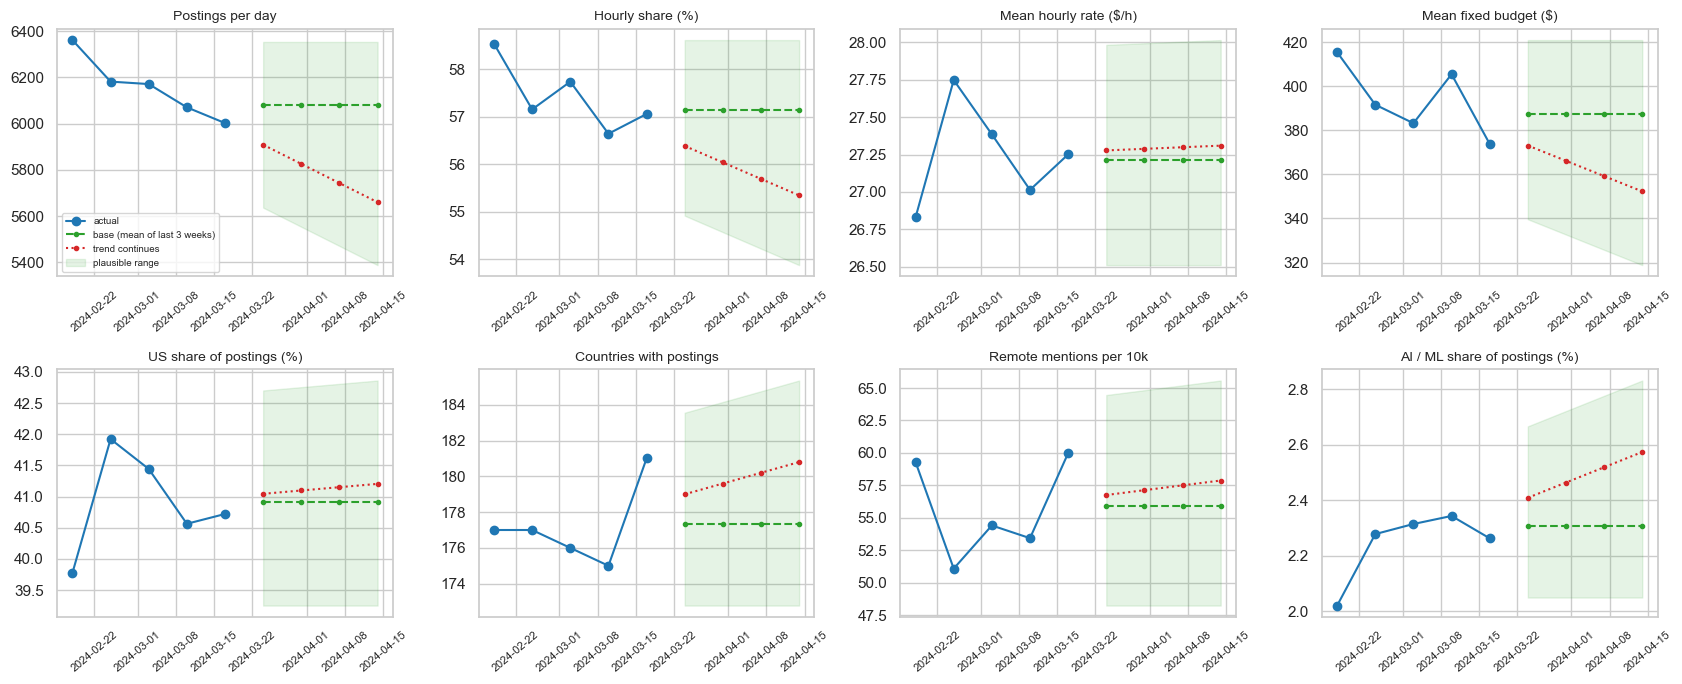


Saved: task8_future_trends_report.md


In [34]:
from IPython.display import Markdown

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (ind, label) in zip(axes.ravel(), INDICATORS.items()):
    sub = scen[scen["indicator"] == ind]
    ax.plot(series.index, series[ind], marker="o", color="tab:blue", label="actual")
    ax.plot(sub["week_start"], sub["base"], color="tab:green", ls="--", marker="o", ms=3, label=f"base ({best8})")
    ax.plot(sub["week_start"], sub["trend_continues"], color="tab:red", ls=":", marker="o", ms=3, label="trend continues")
    ax.fill_between(sub["week_start"], sub["low"], sub["high"], color="tab:green", alpha=0.12, label="plausible range")
    ax.set_title(label, fontsize=10); ax.tick_params(axis="x", rotation=40, labelsize=8)
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

# ---- written report (saved as a Markdown file) ----
g = summary8
vol, p_vol = g.loc["Postings per day"], g.loc["Postings per day", "trend p-value"]
sig_names = g[g["trend significant?"] == "yes"].index.tolist()
last_wk, first_wk = series.index[-1], series.index[0]

    


print("\nSaved: task8_future_trends_report.md")
